# Classical Machine Learning and Biologically Informed Feature Representation for Single-Cell Classification

## Overview

Single-cell RNA sequencing (scRNA-seq) measures gene expression in individual cells, and machine learning can use these high-dimensional profiles to classify cell types. Gene-level models often take hundreds or thousands of genes as input. They can predict well, but linking their predictions to biological processes is hard.

This notebook explores two questions on the PBMC3k dataset:

- **RQ1 - Gene-level classification:** How effectively can classical machine learning methods classify cell types from gene-level expression features?
- **RQ2 - Biologically informed feature representation:** How does replacing genes with pathway-level scores (built from Reactome pathway knowledge) affect classification performance, and what are the trade-offs compared with gene-level features?

**Notebook outline**

1. Setup
2. Data loading and exploratory analysis
3. Train/test split and cross-validation
4. RQ1 - gene-level classification (feature selection, four classical models, error analysis)
5. RQ2 - pathway-level classification (Hallmark exploration, Reactome immune pathways)
6. Comparison, discussion, conclusion and limitations

**Data:** PBMC 3k, loaded from the scanpy package ([dataset description](https://satijalab.org/seurat/articles/pbmc3k_tutorial.html)).

## 1. Setup

Install and import all packages used in the notebook. Imports are collected here so that later cells only contain analysis code. The pathway-level section downloads gene-set libraries through `gseapy`, so it needs internet access.

In [ ]:
%pip install -q scanpy scikit-learn pandas numpy matplotlib seaborn xgboost gseapy

In [2]:
import warnings
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
import xgboost as xgb
from scipy import sparse

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score, cross_validate
from sklearn.feature_selection import SelectKBest, f_classif, VarianceThreshold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
)

warnings.filterwarnings("ignore", category=FutureWarning)

print("scanpy:", version("scanpy"))
print("scikit-learn:", version("scikit-learn"))
print("xgboost:", version("xgboost"))

scanpy: 1.12.5
scikit-learn: 1.6.1
xgboost: 3.4.1


## 2. Data loading and exploratory analysis

### 2.1 Load the dataset

`sc.datasets.pbmc3k_processed()` returns an `AnnData` object: `adata.X` is the expression matrix (cells x genes), `adata.obs` holds per-cell metadata and `adata.var` holds per-gene metadata.

The processed version contains **2,638 cells** and **1,838 genes** (highly variable genes only).

In [3]:
adata = sc.datasets.pbmc3k_processed()
print(adata)   # n_obs = cells, n_vars = genes (features)

print("Number of cells:", adata.n_obs)
print("Number of genes:", adata.n_vars)

AnnData object with n_obs × n_vars = 2638 × 1838
    obs: 'n_genes', 'percent_mito', 'n_counts', 'louvain'
    var: 'n_cells'
    uns: 'draw_graph', 'louvain', 'louvain_colors', 'neighbors', 'pca', 'rank_genes_groups'
    obsm: 'X_pca', 'X_tsne', 'X_umap', 'X_draw_graph_fr'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'
    layers: None (.X)
Number of cells: 2638
Number of genes: 1838


In [4]:
print(adata.obs.head())   # one row per cell: QC metrics and the Louvain cluster label
print(adata.var.head())   # one row per gene: number of cells expressing it

                  n_genes  percent_mito  n_counts          louvain
index                                                             
AAACATACAACCAC-1      781      0.030178    2419.0      CD4 T cells
AAACATTGAGCTAC-1     1352      0.037936    4903.0          B cells
AAACATTGATCAGC-1     1131      0.008897    3147.0      CD4 T cells
AAACCGTGCTTCCG-1      960      0.017431    2639.0  CD14+ Monocytes
AAACCGTGTATGCG-1      522      0.012245     980.0         NK cells
         n_cells
index           
TNFRSF4      155
CPSF3L       202
ATAD3C         9
C1orf86      501
RER1         608


**Interpretation.** The data are high-dimensional relative to the sample size (1,838 features for 2,638 cells). Each cell already carries a Louvain cluster label that has been annotated with a cell-type name; we use these names as the classification target.

### 2.2 Define features and labels

The Louvain cluster column is renamed to `cell_type`. `X` is the gene-expression matrix and `y` the vector of cell-type labels.

In [5]:
# The Louvain clusters in this dataset are already annotated with cell-type names
adata.obs["cell_type"] = adata.obs["louvain"]

X = adata.X                                    # feature matrix (cells x genes)
y = adata.obs["cell_type"].to_numpy()          # target labels (one cell type per cell)

print("X shape (cells x genes):", X.shape)
print("y shape (cell-type labels):", y.shape)

X shape (cells x genes): (2638, 1838)
y shape (cell-type labels): (2638,)


### 2.3 Cell-type distribution

Class balance determines which evaluation metrics are meaningful.

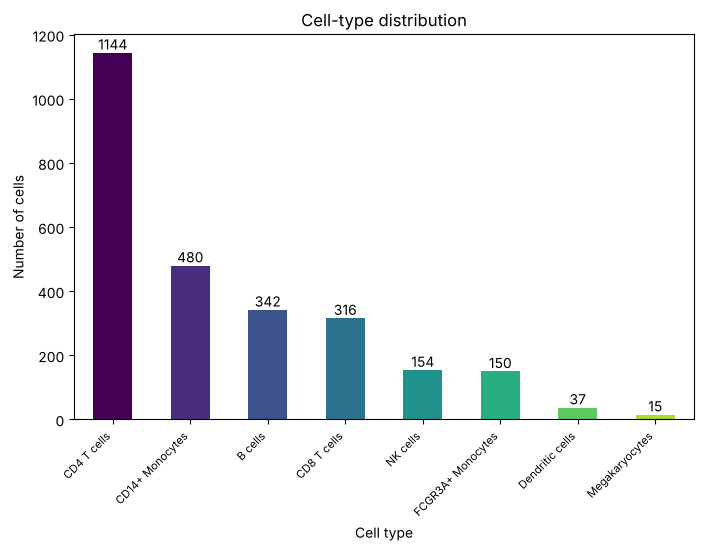

In [6]:
cell_type_counts = adata.obs["cell_type"].value_counts()
num_cell_types = len(cell_type_counts)

cmap = plt.colormaps["viridis"]
colors_for_bars = [cmap(i / num_cell_types) for i in range(num_cell_types)]

ax = cell_type_counts.plot.bar(figsize=(8, 5), color=colors_for_bars)

# Print the count on top of each bar
for container in ax.containers:
    for rect in container:
        height = rect.get_height()
        ax.text(rect.get_x() + rect.get_width() / 2, height, f"{int(height)}", ha="center", va="bottom")

plt.xlabel("Cell type")
plt.ylabel("Number of cells")
plt.title("Cell-type distribution")
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.show()

**Interpretation.** The classes are strongly imbalanced: CD4 T cells are the largest group (1,144 cells), whereas Megakaryocytes are very rare (15 cells) and Dendritic cells have only 37. Accuracy alone can therefore hide poor performance on small classes. Throughout the notebook we report **macro F1** (every class has equal weight) next to accuracy and weighted F1, and use it as the main metric for model selection.

### 2.4 Quality-control metrics

The violin plots show three standard QC metrics: the number of detected genes (`n_genes`), the total RNA count per cell (`n_counts`) and the mitochondrial fraction (`percent_mito`). First for all cells, then split by cell type.

For reference, this is how such plots are normally read:

| Metric trend | Primary concern | Action |
|---|---|---|
| Very low `n_counts` / `n_genes` | Empty droplet / ambient RNA | Filter out lower bound |
| Very high `n_counts` / `n_genes` | Doublet / multiplet | Filter out upper bound |
| High `percent_mito` | Membrane rupture / apoptosis | Filter out upper bound |

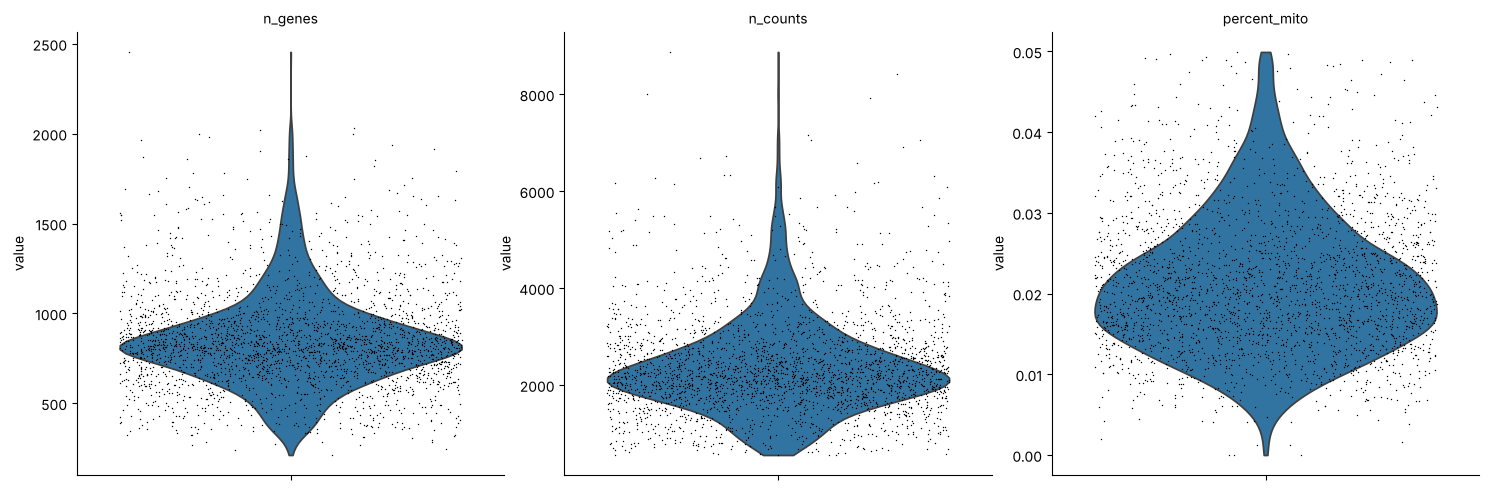

In [7]:
# n_genes: genes detected per cell | n_counts: total RNA molecules per cell | percent_mito: mitochondrial fraction
sc.pl.violin(
    adata,
    ["n_genes", "n_counts", "percent_mito"],
    jitter=0.4,
    multi_panel=True,
)

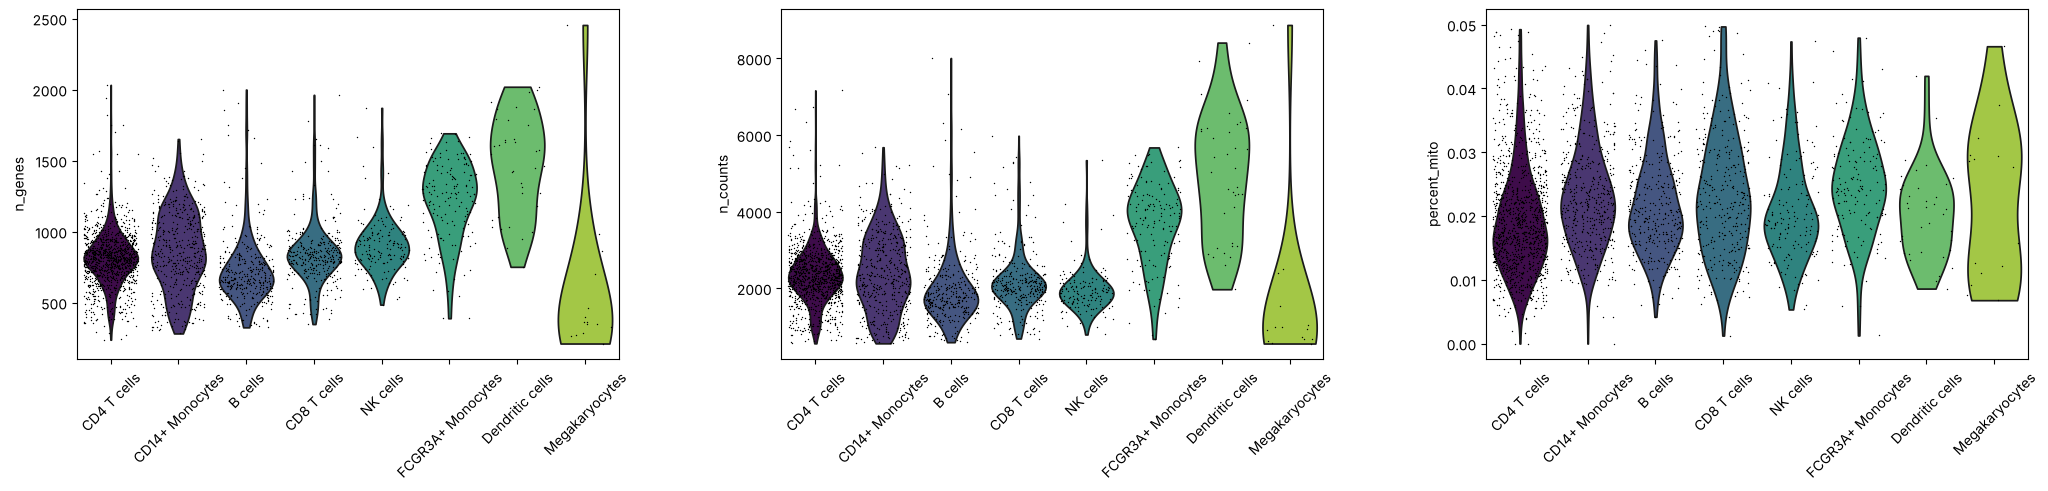

In [8]:
# Same QC metrics, split by cell type (using the same colours as the bar plot)
cell_types_ordered = cell_type_counts.index.tolist()
color_map_dict = {cell_type: colors_for_bars[i] for i, cell_type in enumerate(cell_types_ordered)}

sc.pl.violin(
    adata,
    ["n_genes", "n_counts", "percent_mito"],
    groupby="cell_type",
    jitter=0.4,
    multi_panel=True,
    palette=color_map_dict,
    rotation=45,
)

**Interpretation.** The distributions are compact and `percent_mito` is capped at about 5%, which shows that QC filtering has already been applied to this processed dataset, so no further cell filtering is needed. Differences between cell types are biologically plausible: for example, FCGR3A+ monocytes and dendritic cells are larger cells with higher counts and more detected genes than lymphocytes. Such differences also mean that library-size-related effects could contribute a little to the classification.

## 3. Preprocessing checks, train/test split and cross-validation

### 3.1 Preprocessing status

The processed PBMC3k data already went through QC filtering, library-size normalization, log transformation, highly variable gene selection, regression of confounders and scaling (z-scores per gene). We therefore skip these steps and only check for missing values and zero-variance genes.

In [9]:
# Missing values and zero-variance genes
print("Missing values:", np.isnan(X).sum())

var_filter = VarianceThreshold(threshold=0)
X_filtered = var_filter.fit_transform(X)
print("Genes after zero-variance filter:", X_filtered.shape[1], "of", X.shape[1])

Missing values: 0


Genes after zero-variance filter: 1838 of 1838


**Interpretation.** There are no missing values and no zero-variance genes, so all 1,838 genes are valid features. Because the values are already standardized per gene, expression values below zero simply mean "below the average of all cells".

### 3.2 Stratified train/test split

20% of the cells are held out as a test set. The split is stratified by cell type so that rare classes appear in both sets. The cell indices (`train_idx`, `test_idx`) are stored so that the pathway-level analysis in Section 5 uses **exactly the same cells**.

*Caveat:* the dataset has no donor information. If several cells of one donor appear in both train and test sets, a model may learn donor-specific signals, so cell-level evaluation can overestimate generalization to unseen donors.

In [10]:
# Split the cell indices once, so every later analysis (gene-level and pathway-level)
# can reuse exactly the same train/test cells.
indices = np.arange(adata.n_obs)
train_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    stratify=y,        # keep class proportions; otherwise rare classes could vanish from the test set
    random_state=42,
)

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

split_counts = pd.DataFrame({
    "train": pd.Series(y_train).value_counts(),
    "test": pd.Series(y_test).value_counts(),
})
split_counts["test_fraction"] = (split_counts["test"] / (split_counts["train"] + split_counts["test"])).round(3)
display(split_counts)

Training samples: 2110
Testing samples: 528


,train,test,test_fraction
CD4 T cells,915,229,0.200
CD14+ Monocytes,384,96,0.200
B cells,273,69,0.202
CD8 T cells,253,63,0.199
NK cells,123,31,0.201
FCGR3A+ Monocytes,120,30,0.200
Dendritic cells,30,7,0.189
Megakaryocytes,12,3,0.200


**Interpretation.** Each class keeps about 20% of its cells in the test set. The test set contains only 7 Dendritic cells and 3 Megakaryocytes, so metrics for these classes (and therefore macro F1) are noisy: a single misclassified cell changes the score considerably.

### 3.3 Cross-validation scheme

All hyperparameter tuning uses 5-fold stratified cross-validation on the training set only. The test set is touched only for final evaluation.

In [ ]:
# 5-fold stratified cross-validation, used for all hyperparameter tuning on the training set
kfold = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

### 3.4 Evaluation metrics

- **Accuracy:** the fraction of all cells that are classified correctly.
- **Macro F1:** the unweighted mean of the per-class F1 scores (F1 = harmonic mean of precision and recall). Every cell type counts equally, so it is the primary metric for this imbalanced dataset.
- **Weighted F1:** the mean of per-class F1 scores weighted by class size; it is dominated by large classes.
- **Confusion matrix:** shows which cell types are confused with each other.

## 4. RQ1 - Gene-level classification

### 4.1 Feature selection

Not all 1,838 genes are expected to help equally. `SelectKBest` with an ANOVA F-test ranks genes by how strongly their expression differs between cell types. We tune the number of selected genes (`k`) together with the regularization strength `C` of a Logistic Regression, placing the selection **inside the cross-validation pipeline** so that held-out folds do not influence which genes are chosen.

In [12]:
# Pipeline: ANOVA F-test gene selection -> Logistic Regression.
# Selection happens inside each CV fold, so held-out folds never influence which genes are chosen.
pipeline = Pipeline([
    ("feature_selection", SelectKBest(score_func=f_classif)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42,
    )),
])

# Number of selected genes (k) and regularization strength (C) are tuned together
param_grid = {
    "feature_selection__k": [100, 300, 500, 1000, "all"],
    "classifier__C": [0.01, 0.1, 1, 10],
}

grid_search_fs = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=kfold,
    n_jobs=-1,
    refit=True,
)

# Hyperparameter selection uses the training data only
grid_search_fs.fit(X_train, y_train)

print("Best parameters:", grid_search_fs.best_params_)
print("Best CV Macro F1:", grid_search_fs.best_score_)

# One evaluation on the held-out test set
best_fs_pipeline = grid_search_fs.best_estimator_
y_pred_fs = best_fs_pipeline.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred_fs))
print("Test Macro F1:", f1_score(y_test, y_pred_fs, average="macro"))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_fs))

Best parameters: {'classifier__C': 0.01, 'feature_selection__k': 1000}
Best CV Macro F1: 0.9369350476711272
Test Accuracy: 0.9431818181818182
Test Macro F1: 0.9253902814201108

Classification Report:
                   precision    recall  f1-score   support

          B cells       1.00      1.00      1.00        69
  CD14+ Monocytes       0.95      0.98      0.96        96
      CD4 T cells       0.96      0.95      0.95       229
      CD8 T cells       0.81      0.83      0.82        63
  Dendritic cells       1.00      1.00      1.00         7
FCGR3A+ Monocytes       0.93      0.90      0.92        30
   Megakaryocytes       1.00      0.67      0.80         3
         NK cells       0.97      0.94      0.95        31

         accuracy                           0.94       528
        macro avg       0.95      0.91      0.93       528
     weighted avg       0.94      0.94      0.94       528



**Interpretation.** The best setting is `k = 1000` genes with strong regularization (`C = 0.01`): cross-validated macro F1 is 0.937 and test macro F1 is 0.925 (test accuracy 0.943). Selecting 1,000 genes works as well as using all genes, so a large share of the genes carries little extra information for this task.

In [ ]:
# Fix the selection to the best k (1000 genes), fitted on the training set only
selector = SelectKBest(score_func=f_classif, k=1000)

X_train_selected = selector.fit_transform(X_train, y_train)
X_test_selected = selector.transform(X_test)

The selection is now fixed to the best `k` and fitted on the training data only, so the same reduced feature matrix can be reused for all models.

### 4.2 Redundancy reduction

Strongly correlated genes carry overlapping information. For every pair of selected genes with an absolute Pearson correlation above 0.8, one gene is removed.

In [14]:
gene_names = adata.var_names
selected_genes = gene_names[selector.get_support()]

X_train_selected_df = pd.DataFrame(X_train_selected, columns=selected_genes)
X_test_selected_df = pd.DataFrame(X_test_selected, columns=selected_genes)

# Pairwise absolute Pearson correlation between selected genes (upper triangle only)
corr_matrix = X_train_selected_df.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Drop one gene of every pair with |r| > 0.8 (with a 0.9 threshold no gene was removed)
to_drop = [column for column in upper.columns if (upper[column] > 0.8).any()]

X_train_reduced = X_train_selected_df.drop(columns=to_drop)
X_test_reduced = X_test_selected_df.drop(columns=to_drop)

print("Before redundancy reduction:", X_train_selected_df.shape)
print("After redundancy reduction: ", X_train_reduced.shape)
print("Test set (before / after):  ", X_test_selected_df.shape, X_test_reduced.shape)
print("Removed genes:", to_drop)

Before redundancy reduction: (2110, 1000)
After redundancy reduction:  (2110, 997)
Test set (before / after):   (528, 1000) (528, 997)
Removed genes: ['LY6G6F', 'AP001189.4', 'TYROBP']


**Interpretation.** Only 3 of the 1,000 genes (`LY6G6F`, `AP001189.4`, `TYROBP`) were removed, leaving **997 genes**. Strong pairwise linear redundancy is therefore limited. (With a threshold of 0.9 no gene would have been removed.) This 997-gene set is used for all following models.

For a visual check, the next two cells show the correlations among the 100 top-ranked genes only (a readable size; not used for modelling).

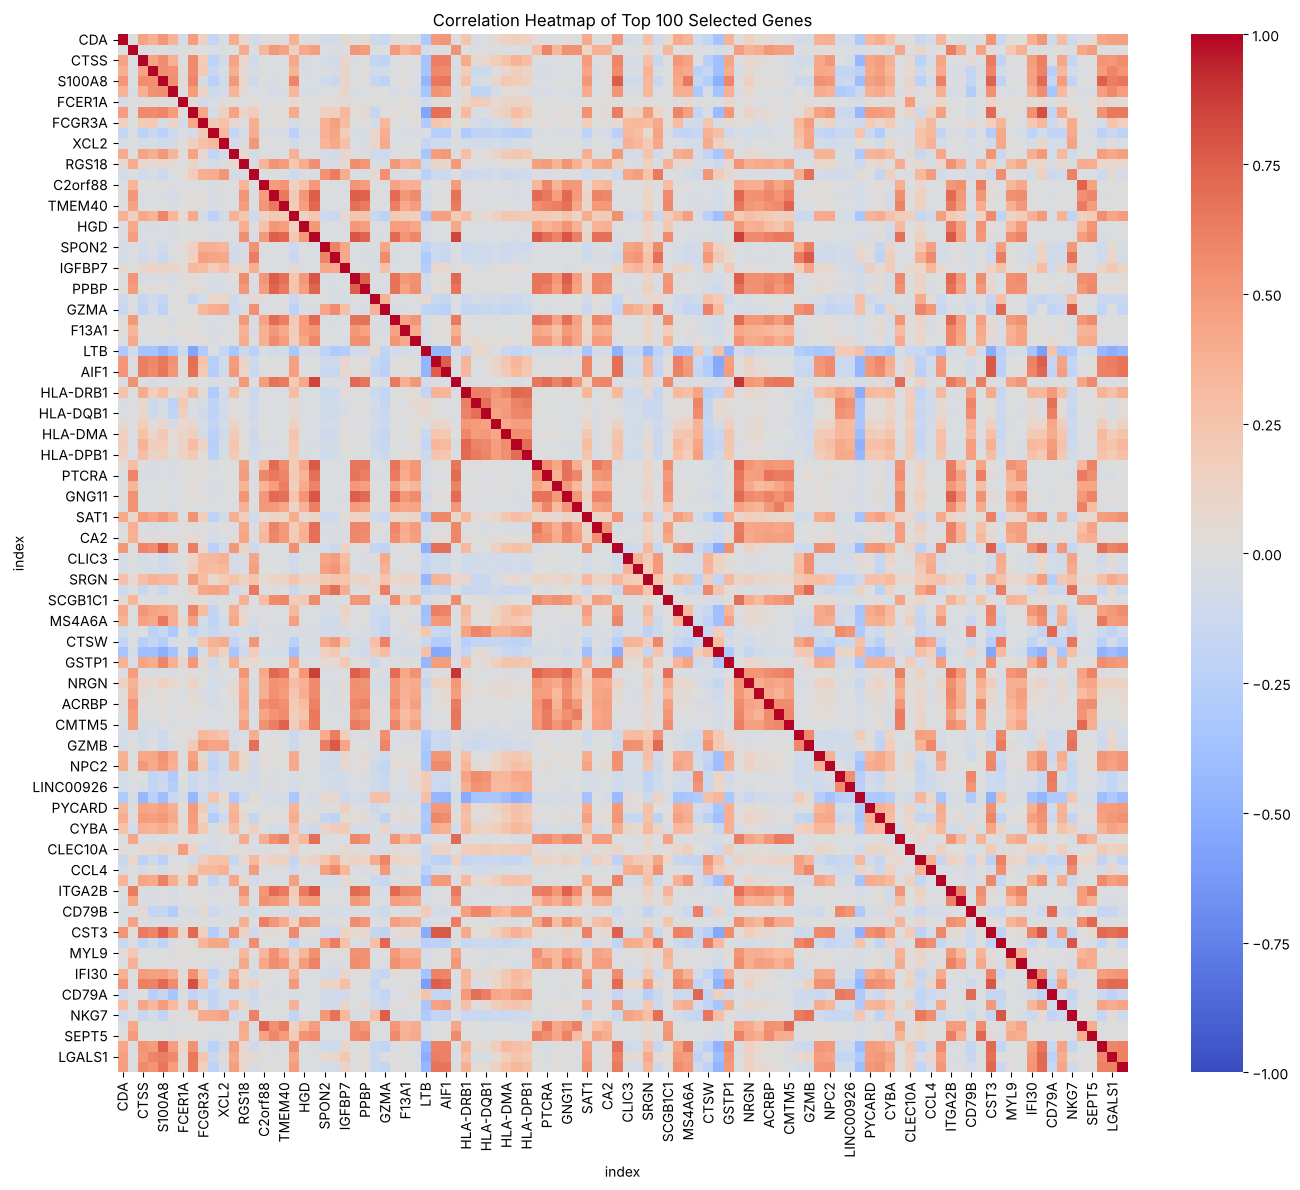

In [15]:
# Visual check on the 100 highest-ranked genes only (readable size; not used for modelling)
selector_100 = SelectKBest(score_func=f_classif, k=100)
X_train_100 = selector_100.fit_transform(X_train, y_train)

X_train_100_df = pd.DataFrame(X_train_100, columns=adata.var_names[selector_100.get_support()])
corr_100 = X_train_100_df.corr()

plt.figure(figsize=(14, 12))
sns.heatmap(corr_100, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Top 100 Selected Genes")
plt.tight_layout()
plt.show()

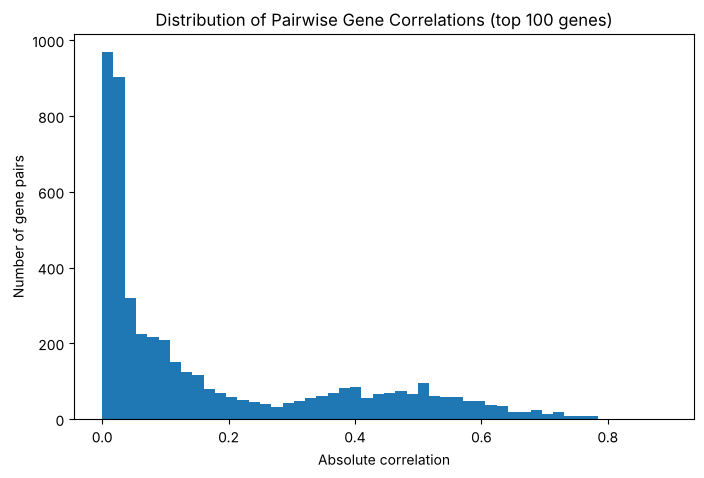

In [16]:
upper_100 = corr_100.where(np.triu(np.ones(corr_100.shape), k=1).astype(bool))
correlations = upper_100.stack().abs()

plt.figure(figsize=(8, 5))
plt.hist(correlations, bins=50)
plt.xlabel("Absolute correlation")
plt.ylabel("Number of gene pairs")
plt.title("Distribution of Pairwise Gene Correlations (top 100 genes)")
plt.show()

**Interpretation.** Most gene pairs have a very low absolute correlation (below 0.2), with a smaller group of moderately correlated pairs around 0.3-0.6 (e.g. genes that mark the same lineage) and none above about 0.8. This agrees with the small number of genes removed above.

### 4.3 Model training and comparison

We compare four classical algorithms on the same split and the same cross-validation folds. Class weights are balanced where the algorithm supports it.

#### 4.3.1 Logistic Regression (linear)

*Baseline:* all 1,838 genes, default regularization (`C = 1`).

In [17]:
# Baseline: Logistic Regression on all 1,838 genes with default regularization (C = 1)
model_lr = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42,
    C=1,
)
model_lr.fit(X_train, y_train)
y_pred_lr = model_lr.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Test Macro F1:", f1_score(y_test, y_pred_lr, average="macro"))
print("Test Weighted F1:", f1_score(y_test, y_pred_lr, average="weighted"))
print()
print(classification_report(y_test, y_pred_lr, digits=3))

Test Accuracy: 0.9450757575757576
Test Macro F1: 0.9382345094102462
Test Weighted F1: 0.9443195750428168

                   precision    recall  f1-score   support

          B cells      1.000     1.000     1.000        69
  CD14+ Monocytes      0.949     0.979     0.964        96
      CD4 T cells      0.949     0.969     0.959       229
      CD8 T cells      0.862     0.794     0.826        63
  Dendritic cells      1.000     0.857     0.923         7
FCGR3A+ Monocytes      0.931     0.900     0.915        30
   Megakaryocytes      1.000     1.000     1.000         3
         NK cells      0.933     0.903     0.918        31

         accuracy                          0.945       528
        macro avg      0.953     0.925     0.938       528
     weighted avg      0.944     0.945     0.944       528



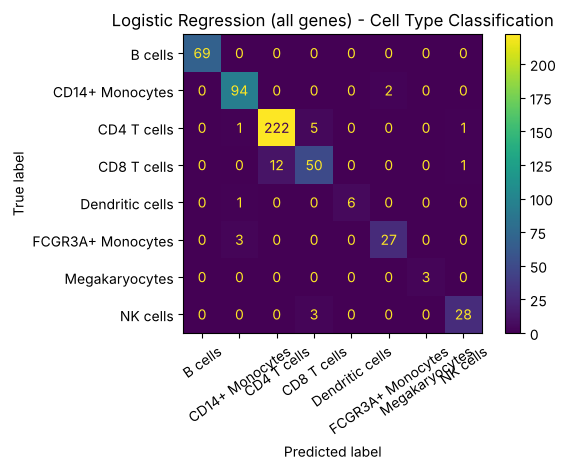

In [18]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr, xticks_rotation=35)
plt.title("Logistic Regression (all genes) - Cell Type Classification")
plt.tight_layout()
plt.show()

**Interpretation.** Even without any tuning, a linear model reaches a test accuracy of 0.945 and macro F1 of 0.938. B cells are classified perfectly; the weakest class is **CD8 T cells** (F1 0.826), and the confusion matrix shows that they are mainly mixed up with CD4 T cells. This is plausible because the two T-cell subsets have very similar transcriptomes.

*Tuned model:* the 997 selected genes, with `C` tuned by cross-validation.

In [19]:
# Tune the regularization strength C on the selected, de-correlated gene set (997 genes)
model_lr = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42,
)

param_grid = {"C": [0.01, 0.1, 1, 10, 100]}
grid_search = GridSearchCV(
    estimator=model_lr,
    param_grid=param_grid,
    cv=kfold,
    scoring="f1_macro",   # macro F1 because the classes are imbalanced
    n_jobs=-1,
)
grid_search.fit(X_train_reduced, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=LogisticRegression(class_weight='balanced',
                                          max_iter=1000, random_state=42),
             n_jobs=-1, param_grid={'C': [0.01, 0.1, 1, 10, 100]},
             scoring='f1_macro')

In [20]:
print(f"Best C: {grid_search.best_params_['C']}")
print(f"Best cross-validated Macro F1: {grid_search.best_score_:.4f}\n")

cv_table = pd.DataFrame(grid_search.cv_results_)
display(
    cv_table[["param_C", "mean_test_score", "std_test_score", "rank_test_score"]]
    .sort_values("rank_test_score")
    .reset_index(drop=True)
)

Best C: 0.01
Best cross-validated Macro F1: 0.9355



,param_C,mean_test_score,std_test_score,rank_test_score
0,0.01,0.935545,0.030979,1
1,0.10,0.930887,0.030576,2
2,1.00,0.925764,0.033990,3
3,100.00,0.923135,0.021186,4
4,10.00,0.923132,0.021477,5


In [21]:
# GridSearchCV has already refit the best model on the full training set
best_model = grid_search.best_estimator_
gene_cv_macro_f1 = grid_search.best_score_      # kept for the final gene vs pathway comparison

y_pred_lr_tuned = best_model.predict(X_test_reduced)

print("Test Accuracy:", accuracy_score(y_test, y_pred_lr_tuned))
print("Test Macro F1:", f1_score(y_test, y_pred_lr_tuned, average="macro"))
print("Test Weighted F1:", f1_score(y_test, y_pred_lr_tuned, average="weighted"))
print()
print(classification_report(y_test, y_pred_lr_tuned, digits=3))

Test Accuracy: 0.9431818181818182
Test Macro F1: 0.9253902814201108
Test Weighted F1: 0.9430955650751517

                   precision    recall  f1-score   support

          B cells      1.000     1.000     1.000        69
  CD14+ Monocytes      0.949     0.979     0.964        96
      CD4 T cells      0.956     0.952     0.954       229
      CD8 T cells      0.812     0.825     0.819        63
  Dendritic cells      1.000     1.000     1.000         7
FCGR3A+ Monocytes      0.931     0.900     0.915        30
   Megakaryocytes      1.000     0.667     0.800         3
         NK cells      0.967     0.935     0.951        31

         accuracy                          0.943       528
        macro avg      0.952     0.907     0.925       528
     weighted avg      0.944     0.943     0.943       528



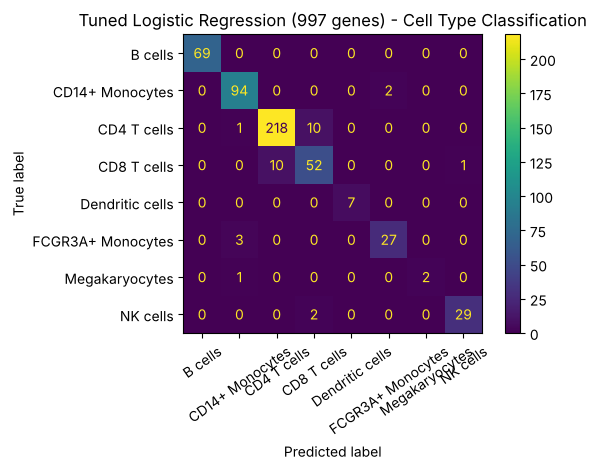

In [22]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr_tuned, xticks_rotation=35)
plt.title("Tuned Logistic Regression (997 genes) - Cell Type Classification")
plt.tight_layout()
plt.show()

**Interpretation.** Stronger regularization (`C = 0.01`) works best in cross-validation (macro F1 0.936), and performance drops slightly for weaker regularization (0.923 at `C = 100`). With many correlated features and few cells, shrinking the coefficients reduces overfitting.

On the held-out test set the tuned model reaches **accuracy 0.943 and macro F1 0.925**. This is slightly lower than the untuned all-gene baseline (macro F1 0.938), but the difference comes from a handful of cells in the smallest classes (e.g. 3 Megakaryocytes), so it is within test-set noise. The compact 997-gene model is kept as the final gene-level model. CD8 T cells remain the hardest class (F1 0.82).

#### 4.3.2 Random Forest (non-linear)

A Random Forest can capture non-linear relationships between genes. First, the number of trees is chosen from the cross-validated macro F1.

*Note:* this sweep was run on all genes without class weights, whereas the final forest below uses the reduced gene set with balanced class weights. Earlier runs without feature selection gave practically identical test results (accuracy 0.917, macro F1 0.858).

In [23]:
# Effect of the number of trees on cross-validated macro F1
tree_numbers = [10, 25, 50, 100, 200, 500]
scores_list = []

for n in tree_numbers:
    model_rf = RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1)
    scores = cross_val_score(model_rf, X_train, y_train, cv=kfold, scoring="f1_macro")
    scores_list.append(scores.mean())
    print(f"n_estimators={n:>3}  CV Macro F1 = {scores.mean():.4f} +/- {scores.std():.4f}")

n_estimators= 10  CV Macro F1 = 0.7806 +/- 0.0230


n_estimators= 25  CV Macro F1 = 0.8250 +/- 0.0231


n_estimators= 50  CV Macro F1 = 0.8393 +/- 0.0304


n_estimators=100  CV Macro F1 = 0.8418 +/- 0.0347


n_estimators=200  CV Macro F1 = 0.8463 +/- 0.0305


n_estimators=500  CV Macro F1 = 0.8401 +/- 0.0309


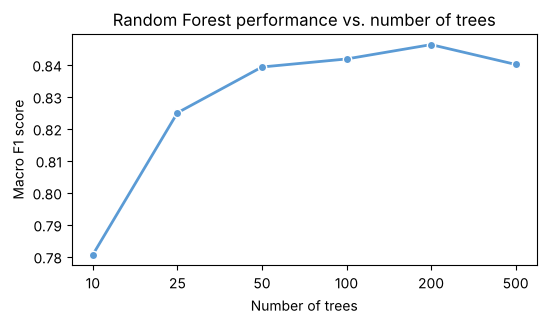

In [24]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(range(len(tree_numbers)), scores_list, marker="o", color="#5B9BD5", linewidth=2, markeredgecolor="white")
ax.set_xticks(range(len(tree_numbers)))
ax.set_xticklabels([f"{x:g}" for x in tree_numbers])
plt.xlabel("Number of trees")
plt.ylabel("Macro F1 score")
plt.title("Random Forest performance vs. number of trees")
plt.show()

In [25]:
# Final Random Forest: 200 trees, class-balanced, trained on the reduced gene set
best_rf = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)
best_rf.fit(X_train_reduced, y_train)
y_pred_rf_tuned = best_rf.predict(X_test_reduced)

print("Test Accuracy:", accuracy_score(y_test, y_pred_rf_tuned))
print("Test Macro F1:", f1_score(y_test, y_pred_rf_tuned, average="macro"))
print("Test Weighted F1:", f1_score(y_test, y_pred_rf_tuned, average="weighted"))
print()
print(classification_report(y_test, y_pred_rf_tuned, digits=3))

Test Accuracy: 0.9166666666666666
Test Macro F1: 0.8580662805292908
Test Weighted F1: 0.912071002121205

                   precision    recall  f1-score   support

          B cells      1.000     1.000     1.000        69
  CD14+ Monocytes      0.888     0.990     0.936        96
      CD4 T cells      0.915     0.983     0.947       229
      CD8 T cells      0.833     0.635     0.721        63
  Dendritic cells      1.000     0.571     0.727         7
FCGR3A+ Monocytes      0.958     0.767     0.852        30
   Megakaryocytes      1.000     0.667     0.800         3
         NK cells      0.929     0.839     0.881        31

         accuracy                          0.917       528
        macro avg      0.940     0.806     0.858       528
     weighted avg      0.916     0.917     0.912       528



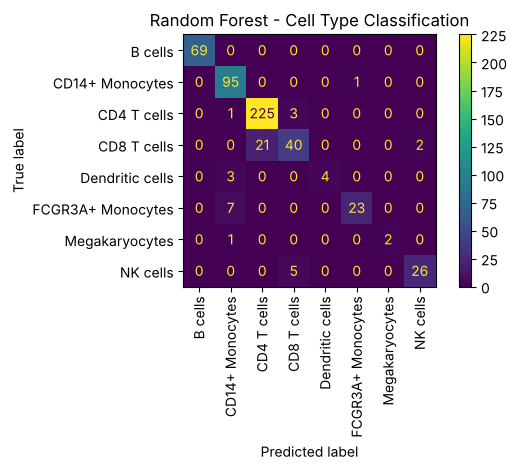

In [26]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf_tuned, xticks_rotation=90)
plt.title("Random Forest - Cell Type Classification")
plt.tight_layout()
plt.show()

**Interpretation.** Performance improves up to about 200 trees (CV macro F1 0.846) and then plateaus, so 200 trees are used. The Random Forest is clearly weaker than Logistic Regression (test macro F1 0.858 vs 0.925). Its CD4 recall is the highest of all models (0.983) but its CD8 recall is the lowest (0.635): it tends to assign ambiguous T cells to the large CD4 class. Tree ensembles are less well suited to this kind of smooth, high-dimensional expression data with few cells.

#### 4.3.3 Support Vector Machine

An RBF-kernel SVM is a strong choice for few cells with many features. `C` and `gamma` are tuned by cross-validation.

In [27]:
# RBF-kernel SVM; tune C and gamma with 5-fold CV on the reduced gene set
model_svc = SVC(class_weight="balanced", random_state=42)

param_grid_svc = {
    "C": [0.1, 1, 10],
    "gamma": ["scale", "auto", 0.1, 1],
}

grid_search_svc = GridSearchCV(
    estimator=model_svc,
    param_grid=param_grid_svc,
    cv=kfold,
    scoring="f1_macro",
    n_jobs=-1,
)
grid_search_svc.fit(X_train_reduced, y_train)

print("Best parameters for SVC:", grid_search_svc.best_params_)
print("Best CV Macro F1 for SVC:", grid_search_svc.best_score_)

best_svc_model = grid_search_svc.best_estimator_
y_pred_svc = best_svc_model.predict(X_test_reduced)

print("\nTest Accuracy for SVC:", accuracy_score(y_test, y_pred_svc))
print("Test Macro F1 for SVC:", f1_score(y_test, y_pred_svc, average="macro"))
print("\nClassification Report for SVC:")
print(classification_report(y_test, y_pred_svc))

Best parameters for SVC: {'C': 1, 'gamma': 'auto'}
Best CV Macro F1 for SVC: 0.8234763856636629



Test Accuracy for SVC: 0.9412878787878788
Test Macro F1 for SVC: 0.9195137467718792

Classification Report for SVC:
                   precision    recall  f1-score   support

          B cells       1.00      1.00      1.00        69
  CD14+ Monocytes       0.95      0.99      0.97        96
      CD4 T cells       0.94      0.95      0.95       229
      CD8 T cells       0.81      0.79      0.80        63
  Dendritic cells       1.00      0.86      0.92         7
FCGR3A+ Monocytes       0.97      0.93      0.95        30
   Megakaryocytes       1.00      0.67      0.80         3
         NK cells       1.00      0.94      0.97        31

         accuracy                           0.94       528
        macro avg       0.96      0.89      0.92       528
     weighted avg       0.94      0.94      0.94       528



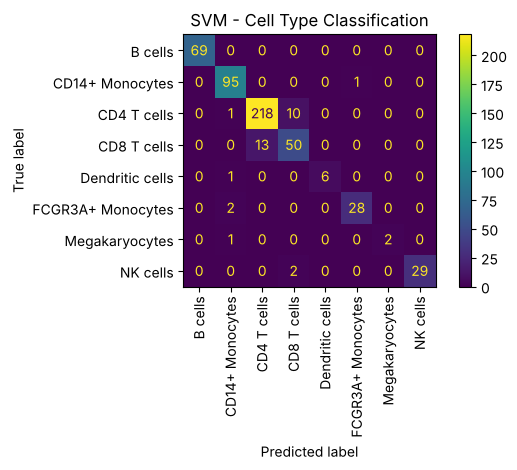

In [28]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_svc, xticks_rotation=90)
plt.title("SVM - Cell Type Classification")
plt.tight_layout()
plt.show()

**Interpretation.** The SVM reaches a test macro F1 of 0.920 and accuracy of 0.941, close to Logistic Regression. Its cross-validated macro F1 (0.823) is much lower than its test macro F1. The small classes have only 2-3 cells per validation fold, so fold-level macro F1 is very unstable; the CV value should therefore be compared across settings, not with the test score.

#### 4.3.4 XGBoost

Gradient-boosted trees are a strong default for tabular data. Here XGBoost is evaluated with default hyperparameters (no tuning), because tuning was computationally expensive and not the focus of this project.

In [29]:
# XGBoost needs integer class labels
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)

# Default hyperparameters (no tuning)
xgb_baseline = xgb.XGBClassifier(
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1,
)

cv_scores = cross_val_score(
    xgb_baseline,
    X_train_reduced,
    y_train_encoded,
    cv=kfold,
    scoring="f1_macro",
    n_jobs=-1,
)

print("Cross-validation Macro F1 per fold:", np.round(cv_scores, 4))
print(f"Mean CV Macro F1: {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}")

Cross-validation Macro F1 per fold: [0.8904 0.8734 0.8843 0.9447 0.911 ]
Mean CV Macro F1: 0.9007 +/- 0.0251


In [30]:
xgb_baseline.fit(X_train_reduced, y_train_encoded)

# Convert integer predictions back to cell-type names
y_pred_xgb_baseline = le.inverse_transform(xgb_baseline.predict(X_test_reduced))

print("Test Accuracy:", accuracy_score(y_test, y_pred_xgb_baseline))
print("Test Macro F1:", f1_score(y_test, y_pred_xgb_baseline, average="macro"))
print()
print(classification_report(y_test, y_pred_xgb_baseline))

Test Accuracy: 0.9299242424242424
Test Macro F1: 0.8929593191445682

                   precision    recall  f1-score   support

          B cells       0.99      1.00      0.99        69
  CD14+ Monocytes       0.95      0.98      0.96        96
      CD4 T cells       0.94      0.95      0.95       229
      CD8 T cells       0.78      0.78      0.78        63
  Dendritic cells       1.00      0.71      0.83         7
FCGR3A+ Monocytes       0.93      0.93      0.93        30
   Megakaryocytes       1.00      0.67      0.80         3
         NK cells       0.96      0.84      0.90        31

         accuracy                           0.93       528
        macro avg       0.94      0.86      0.89       528
     weighted avg       0.93      0.93      0.93       528



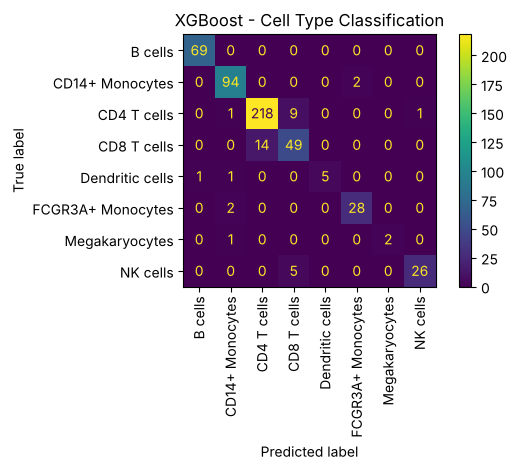

In [31]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_xgb_baseline, xticks_rotation=90)
plt.title("XGBoost - Cell Type Classification")
plt.tight_layout()
plt.show()

**Interpretation.** Default XGBoost reaches a test accuracy of 0.930 and macro F1 of 0.893, between Random Forest and the linear models. CD8 T cells are again the weakest class (F1 0.78).

#### 4.3.5 Model comparison

All models are summarized in one table (test set), together with the recall of the two T-cell classes. The helper `top_confusions` is also reused for the pathway-level model later.

In [32]:
def top_confusions(y_true, y_pred, n=6):
    """Return the n most frequent misclassifications as a (true, predicted, count) table."""
    labels = np.unique(y_true)
    cm = pd.DataFrame(confusion_matrix(y_true, y_pred, labels=labels), index=labels, columns=labels)
    errors = cm.stack().rename_axis(["True", "Predicted"]).reset_index(name="Count")
    errors = errors[errors["True"] != errors["Predicted"]]
    return errors.sort_values("Count", ascending=False).head(n).reset_index(drop=True)


model_predictions = {
    "Logistic Regression (tuned)": y_pred_lr_tuned,
    "Random Forest (200 trees)": y_pred_rf_tuned,
    "SVM (RBF, tuned)": y_pred_svc,
    "XGBoost (default)": y_pred_xgb_baseline,
}

rows = []
for name, pred in model_predictions.items():
    report = classification_report(y_test, pred, output_dict=True, zero_division=0)
    rows.append({
        "Model": name,
        "Test accuracy": accuracy_score(y_test, pred),
        "Test macro F1": f1_score(y_test, pred, average="macro"),
        "Test weighted F1": f1_score(y_test, pred, average="weighted"),
        "CD4 recall": report["CD4 T cells"]["recall"],
        "CD8 recall": report["CD8 T cells"]["recall"],
    })

model_comparison = pd.DataFrame(rows).set_index("Model").round(3)
display(model_comparison)

print("Most frequent errors of the tuned Logistic Regression model:")
display(top_confusions(y_test, y_pred_lr_tuned))

,Test accuracy,Test macro F1,Test weighted F1,CD4 recall,CD8 recall
Model,,,,,
Logistic Regression (tuned),0.943,0.925,0.943,0.952,0.825
Random Forest (200 trees),0.917,0.858,0.912,0.983,0.635
"SVM (RBF, tuned)",0.941,0.920,0.941,0.952,0.794
XGBoost (default),0.930,0.893,0.929,0.952,0.778


Most frequent errors of the tuned Logistic Regression model:


,True,Predicted,Count
0,CD4 T cells,CD8 T cells,10
1,CD8 T cells,CD4 T cells,10
2,FCGR3A+ Monocytes,CD14+ Monocytes,3
3,CD14+ Monocytes,FCGR3A+ Monocytes,2
4,NK cells,CD8 T cells,2
5,Megakaryocytes,CD14+ Monocytes,1


**Interpretation.** Logistic Regression is the best model on every metric (test macro F1 0.925), followed by the SVM (0.920), XGBoost (0.893) and Random Forest (0.858). Simple regularized linear models are therefore enough for this dataset and are also the easiest to interpret, so they are used for the rest of the analysis. For every model **CD8 recall is the lowest of the main classes** (0.635-0.825), and in the tuned Logistic Regression the two largest error types are CD4 -> CD8 (10 cells) and CD8 -> CD4 (10 cells).

### 4.4 Error analysis: why are some CD8 T cells misclassified?

Overall accuracy hides that CD4/CD8 discrimination is the main weakness. We ask whether the errors are specific to one algorithm or shared by all of them.

#### 4.4.1 Cells misclassified by all models

For every true CD8 T cell we count how many of the four models predict CD4 T cells.

In [33]:
results = pd.DataFrame({
    "True": y_test,
    "LR": y_pred_lr_tuned,
    "RF": y_pred_rf_tuned,
    "SVM": y_pred_svc,
    "XGBoost": y_pred_xgb_baseline,
})
models = ["LR", "RF", "SVM", "XGBoost"]

# For every true CD8 T cell, count how many of the four models predict CD4 T cells
cd8 = results[results["True"] == "CD8 T cells"].copy()
cd8["n_models_predict_cd4"] = (cd8[models] == "CD4 T cells").sum(axis=1)

print("Number of models (out of 4) that predict CD4 for a true CD8 cell:")
print(cd8["n_models_predict_cd4"].value_counts().sort_index())

# CD8 cells that all four models call CD4
common_errors = cd8[cd8["n_models_predict_cd4"] == 4]
misclassified_idx = common_errors.index       # row positions in the test set
print("\nCommonly misclassified CD8 cells (test-set row index):", misclassified_idx.tolist())
print(f"{len(misclassified_idx)} of {len(cd8)} CD8 T cells ({len(misclassified_idx) / len(cd8):.1%})")

Number of models (out of 4) that predict CD4 for a true CD8 cell:
n_models_predict_cd4
0    42
1     7
2     1
3     3
4    10
Name: count, dtype: int64

Commonly misclassified CD8 cells (test-set row index): [41, 71, 76, 191, 345, 360, 399, 431, 459, 478]
10 of 63 CD8 T cells (15.9%)


**Interpretation.** Out of 63 CD8 T cells in the test set, 42 are never confused with CD4, but **10 cells (15.9%) are called CD4 by all four models**. The problem is therefore not caused by one algorithm. It points to a subset of CD8 T cells whose expression profile looks like CD4 T cells in the current feature space. Their test-set row indices are listed above; they are analysed in the next steps.

#### 4.4.2 Which genes does the Logistic Regression model use?

The Logistic Regression has one coefficient per gene and class. The bar plots show, for each cell type, the 10 genes with the most positive (green) and most negative (red) coefficients. Because the expression values are standardized, coefficients are directly comparable between genes.

Coefficient matrix shape (classes x genes): (8, 997)


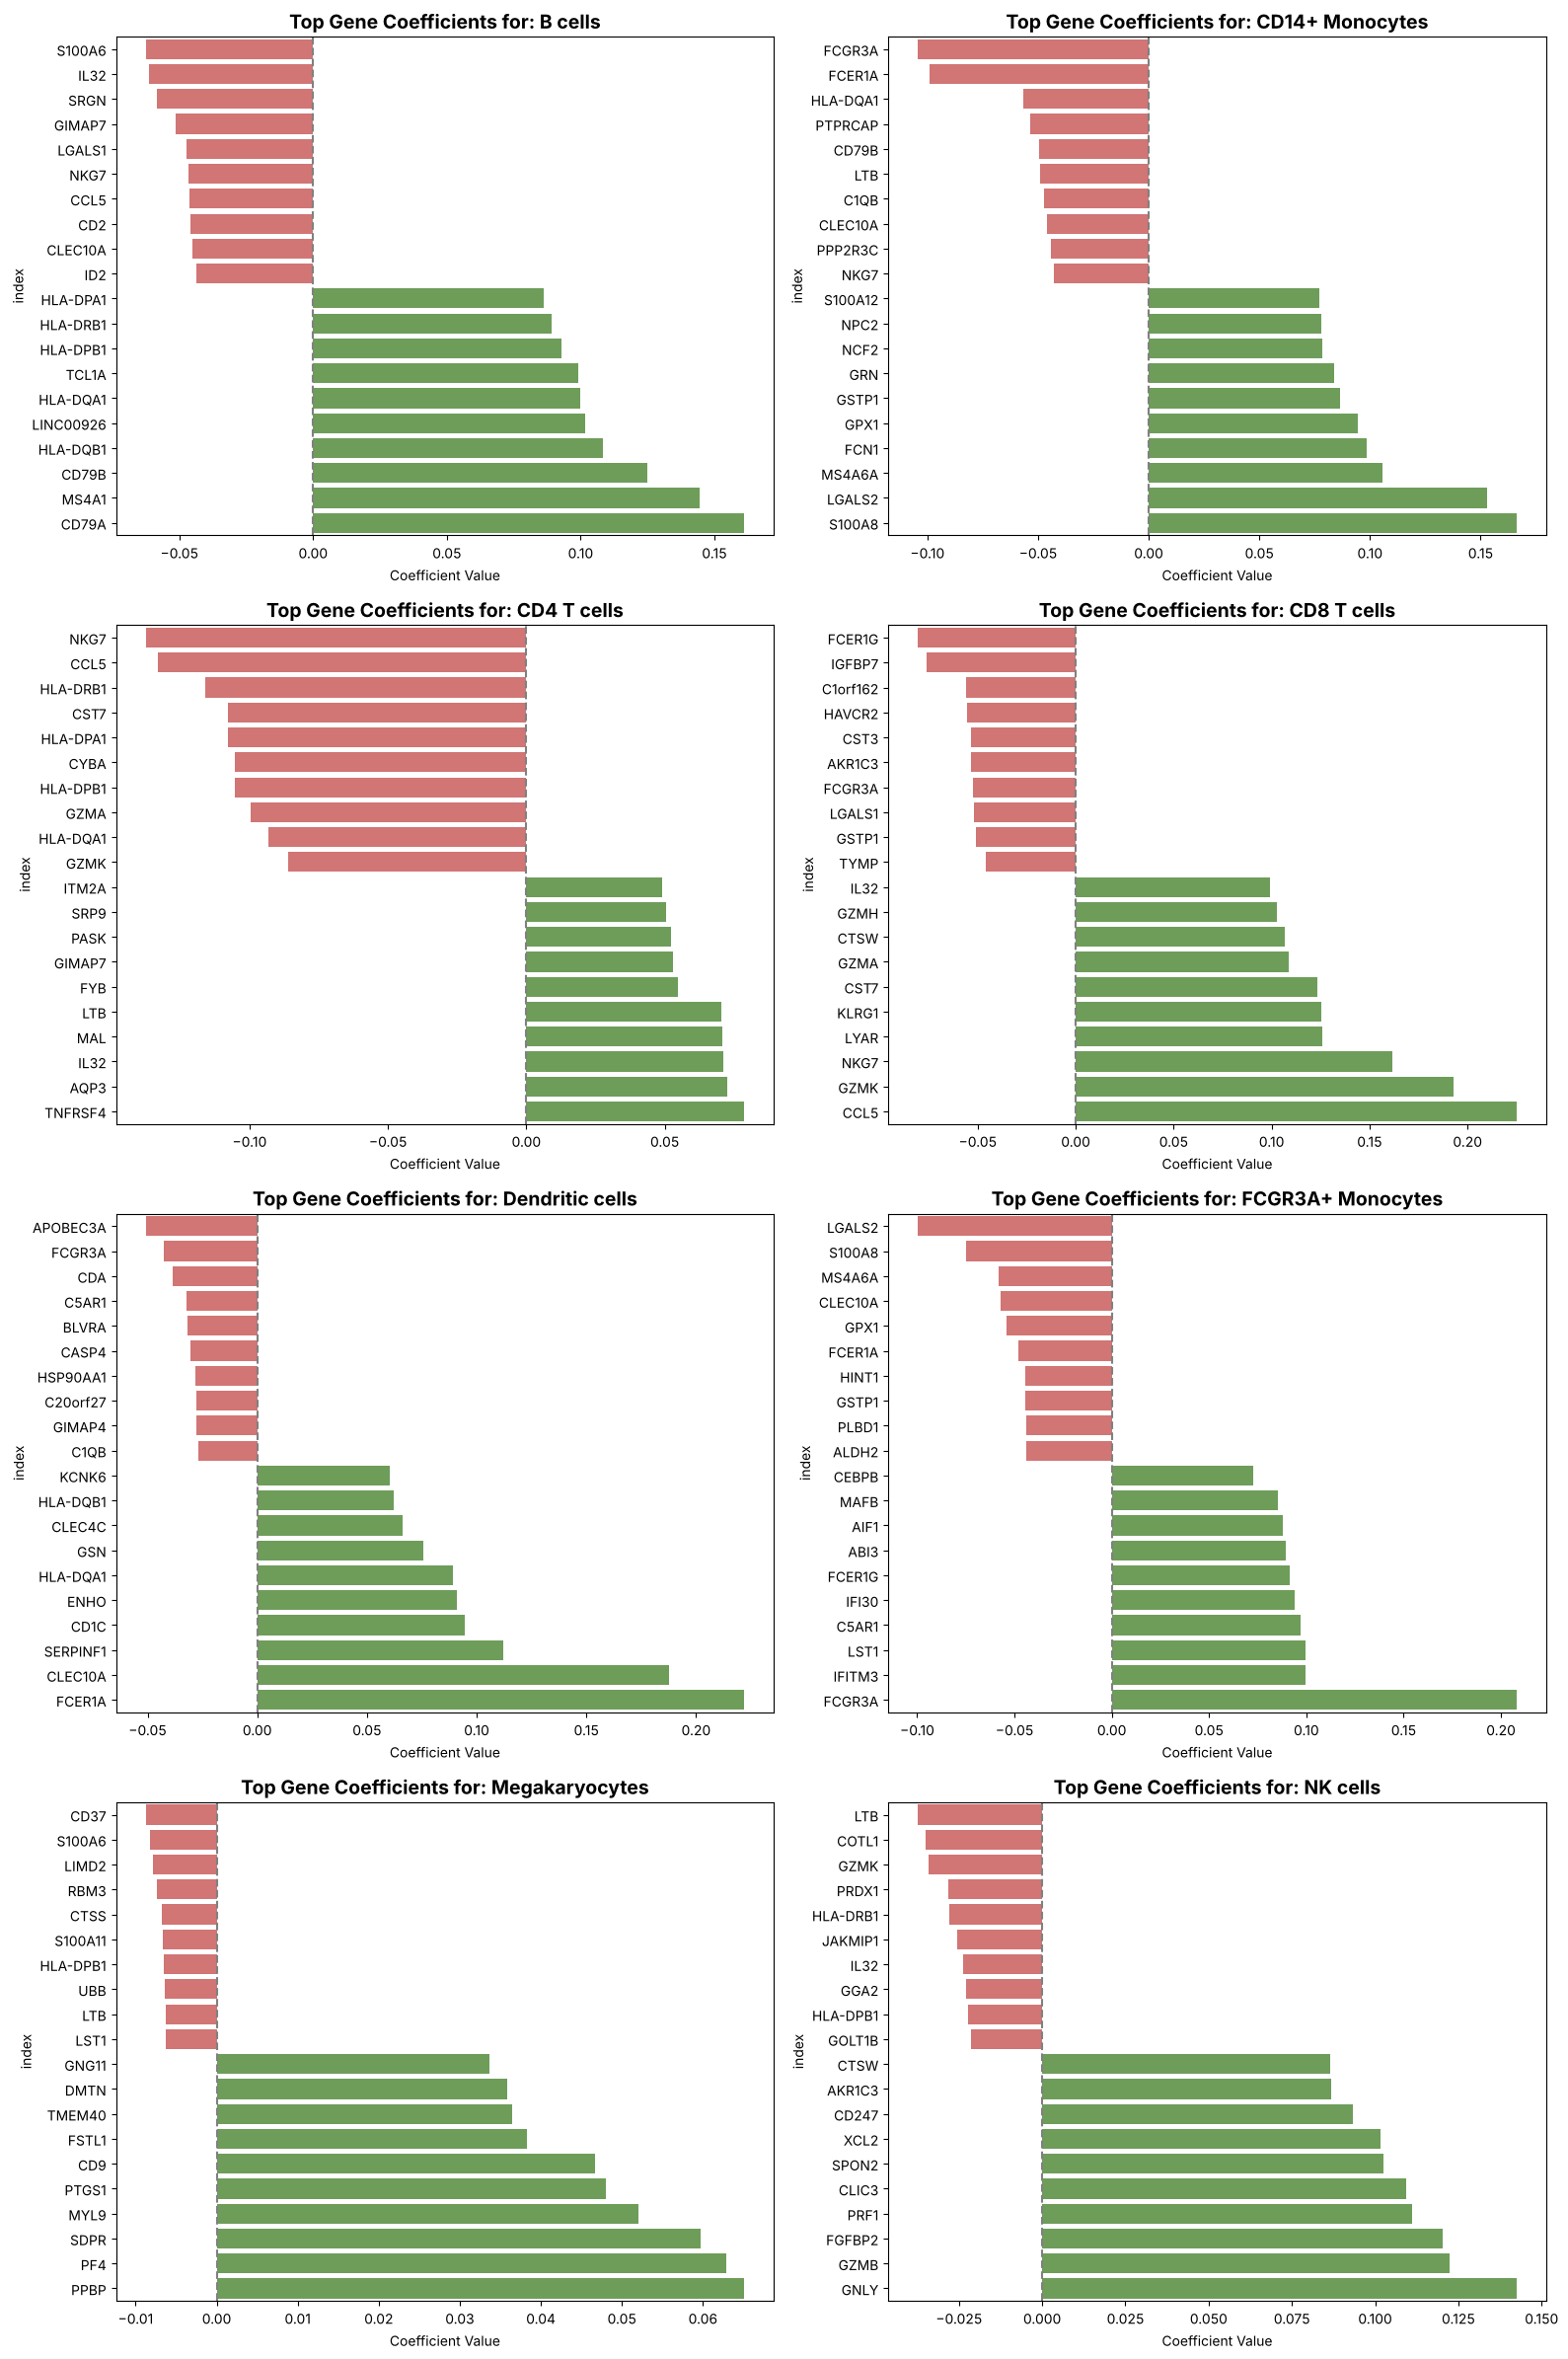

In [34]:
# Coefficients of the tuned LR model: one row per cell type, one column per gene
coef_df = pd.DataFrame(
    best_model.coef_,
    index=best_model.classes_,
    columns=X_train_reduced.columns,
)
print("Coefficient matrix shape (classes x genes):", coef_df.shape)

# Top 10 positive and top 10 negative genes for every cell type
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(16, 24))
axes = axes.flatten()

for i, cell_type in enumerate(best_model.classes_):
    sorted_coefs = coef_df.loc[cell_type].sort_values()
    top_genes_cls = pd.concat([sorted_coefs.head(10), sorted_coefs.tail(10)])
    bar_colors = ["#E06666" if val < 0 else "#6AA84F" for val in top_genes_cls.values]

    sns.barplot(x=top_genes_cls.values, y=top_genes_cls.index, hue=top_genes_cls.index,
                palette=bar_colors, legend=False, ax=axes[i])
    axes[i].set_title(f"Top Gene Coefficients for: {cell_type}", fontsize=14, fontweight="bold")
    axes[i].set_xlabel("Coefficient Value", fontsize=10)
    axes[i].axvline(x=0, color="grey", linestyle="--")

plt.tight_layout()
plt.show()

In [35]:
cd4_coef = coef_df.loc["CD4 T cells"]
cd8_coef = coef_df.loc["CD8 T cells"]

print("Top 15 CD4 genes (by |coefficient|):")
print(cd4_coef.abs().sort_values(ascending=False).head(15))

print("\nTop 15 CD8 genes (by |coefficient|):")
print(cd8_coef.abs().sort_values(ascending=False).head(15))

Top 15 CD4 genes (by |coefficient|):
index
NKG7        0.137467
CCL5        0.133027
HLA-DRB1    0.116140
CST7        0.107790
HLA-DPA1    0.107663
CYBA        0.105441
HLA-DPB1    0.105323
GZMA        0.099704
HLA-DQA1    0.093316
GZMK        0.085966
CTSW        0.085573
TNFRSF4     0.078668
HLA-DQB1    0.077842
GZMH        0.077386
CD79B       0.076687
Name: CD4 T cells, dtype: float64

Top 15 CD8 genes (by |coefficient|):
index
CCL5        0.224868
GZMK        0.192807
NKG7        0.161495
LYAR        0.125668
KLRG1       0.125238
CST7        0.123327
GZMA        0.108812
CTSW        0.106630
GZMH        0.102628
IL32        0.099346
CD2         0.084900
FCER1G      0.080442
IGFBP7      0.075903
SAMD3       0.074888
CDC42EP3    0.068400
Name: CD8 T cells, dtype: float64


**Interpretation.** The top genes are biologically sensible: B cells are driven by `CD79A`, `CD79B`, `MS4A1` and MHC class II genes; CD14+ monocytes by `S100A8`, `LGALS2` and `FCN1`; FCGR3A+ monocytes by `FCGR3A`; NK cells by `GNLY`, `GZMB` and `PRF1`; Megakaryocytes by `PPBP` and `PF4`; and CD8 T cells by `CCL5`, `GZMK`, `NKG7` and other cytotoxic genes. The model therefore learns known marker biology rather than noise.

The CD4 and CD8 classifiers rely on a substantially overlapping set of genes (for example `NKG7`, `CCL5`, `CST7`, `GZMA`, `GZMK`), but with opposite signs, which is exactly what makes this pair difficult.

In a multinomial Logistic Regression, the difference of coefficients `beta_CD8 - beta_CD4` is the weight of each gene in the **CD8-versus-CD4 log-odds**. The table and plot show the 20 genes with the largest absolute difference.

In [36]:
# In multinomial LR, (beta_CD8 - beta_CD4) is the weight of each gene in the CD8-vs-CD4 log-odds
coef_comparison = pd.DataFrame({"CD4_coef": cd4_coef, "CD8_coef": cd8_coef})
coef_comparison["difference"] = coef_comparison["CD8_coef"] - coef_comparison["CD4_coef"]
coef_comparison["abs_difference"] = coef_comparison["difference"].abs()

top20_diff = coef_comparison.sort_values("abs_difference", ascending=False).head(20)
top_diff_genes = top20_diff.index.tolist()
display(top20_diff)

,CD4_coef,CD8_coef,difference,abs_difference
index,,,,
CCL5,-0.133027,0.224868,0.357895,0.357895
NKG7,-0.137467,0.161495,0.298962,0.298962
GZMK,-0.085966,0.192807,0.278773,0.278773
CST7,-0.107790,0.123327,0.231117,0.231117
GZMA,-0.099704,0.108812,0.208516,0.208516
LYAR,-0.074994,0.125668,0.200661,0.200661
CTSW,-0.085573,0.106630,0.192203,0.192203
GZMH,-0.077386,0.102628,0.180014,0.180014
KLRG1,-0.054173,0.125238,0.179411,0.179411


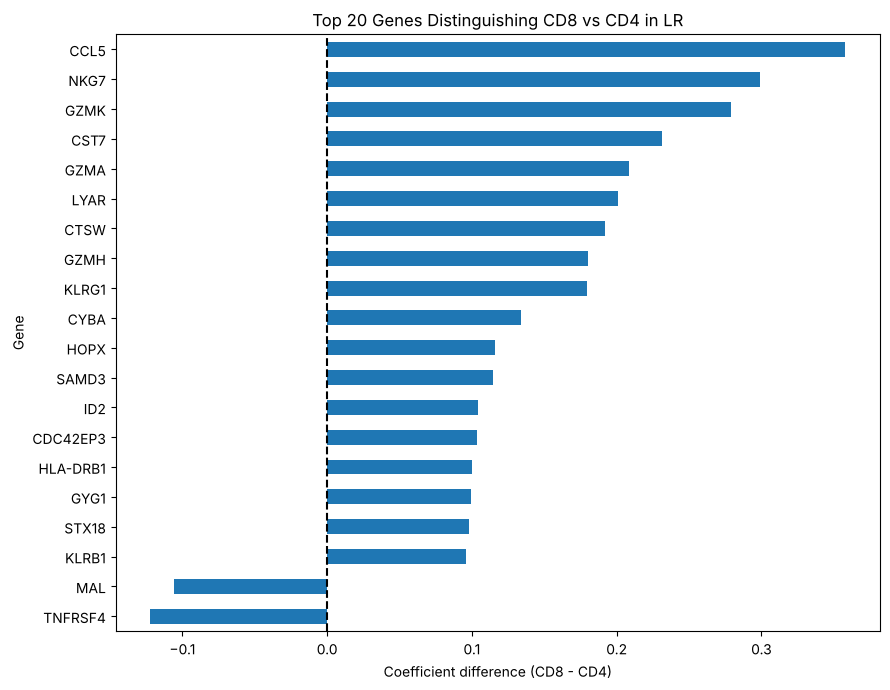

In [37]:
top20_plot = top20_diff["difference"].sort_values()

plt.figure(figsize=(9, 7))
top20_plot.plot(kind="barh")
plt.axvline(0, color="black", linestyle="--")
plt.xlabel("Coefficient difference (CD8 - CD4)")
plt.ylabel("Gene")
plt.title("Top 20 Genes Distinguishing CD8 vs CD4 in LR")
plt.tight_layout()
plt.show()

**Interpretation.**

- **Positive differences** (higher expression favours CD8): `CCL5`, `NKG7`, `GZMK`, `CST7`, `GZMA`, `CTSW`, `GZMH`, `KLRG1`, `LYAR`. The model relies strongly on cytotoxicity-associated expression to call CD8 T cells.
- **Negative differences** (higher expression favours CD4): `TNFRSF4` and `MAL`. These are CD4 / naive T-cell associated genes.

CD8 T cells with weak cytotoxic expression, or stronger CD4-associated expression, are therefore expected to be pushed towards CD4. The coefficients describe how the *model* decides, not whether a gene is biologically causal.

#### 4.4.3 Expression profile of the misclassified cells

The heatmap compares the mean expression of the 20 most discriminative genes in three groups: correctly classified CD4 cells, correctly classified CD8 cells and the 10 commonly misclassified CD8 cells.

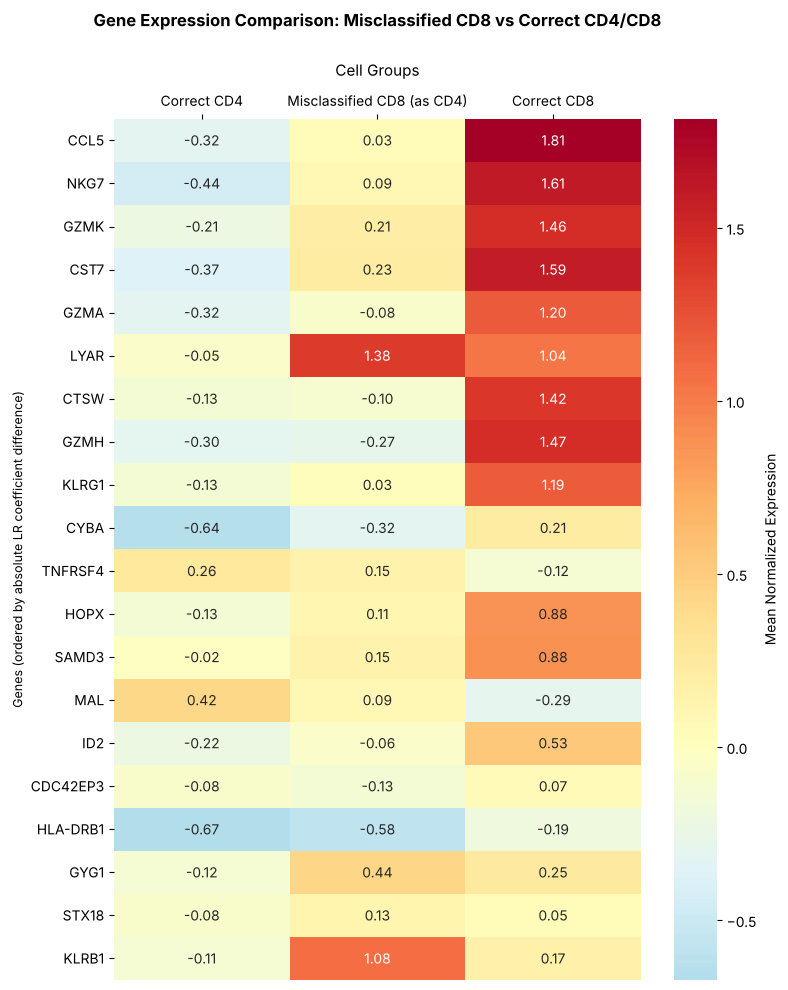

In [38]:
# Test-set expression of the 997 selected genes, indexed like `results`
X_test_df = X_test_reduced.copy()
X_test_df.index = results.index

# Three groups of cells to compare
correct_cd8_idx = cd8[cd8["LR"] == "CD8 T cells"].index
cd4_test = results[results["True"] == "CD4 T cells"]
correct_cd4_idx = cd4_test[cd4_test["LR"] == "CD4 T cells"].index

X_test_df["Group"] = "Other"
X_test_df.loc[correct_cd4_idx, "Group"] = "Correct CD4"
X_test_df.loc[correct_cd8_idx, "Group"] = "Correct CD8"
X_test_df.loc[misclassified_idx, "Group"] = "Misclassified CD8 (as CD4)"

group_names = ["Correct CD4", "Misclassified CD8 (as CD4)", "Correct CD8"]
plot_df = X_test_df[X_test_df["Group"].isin(group_names)].copy()

# Mean expression of the 20 most discriminative genes in each group (genes on the y-axis)
group_means = plot_df.groupby("Group")[top_diff_genes].mean().reindex(group_names)

plt.figure(figsize=(8, 10))
ax = sns.heatmap(
    group_means.T,
    cmap="RdYlBu_r",
    center=0,
    annot=True,
    fmt=".2f",
    cbar_kws={"label": "Mean Normalized Expression"},
)
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")
plt.title("Gene Expression Comparison: Misclassified CD8 vs Correct CD4/CD8", fontsize=12, fontweight="bold", pad=25)
plt.xlabel("Cell Groups", fontsize=11, labelpad=12)
plt.ylabel("Genes (ordered by absolute LR coefficient difference)", fontsize=9)
plt.xticks(ha="center")
plt.tight_layout()
plt.show()

**Interpretation.** For the main cytotoxic genes (`CCL5`, `NKG7`, `GZMK`, `CST7`, `GZMA`, `CTSW`, `GZMH`, `KLRG1`) the misclassified CD8 cells have mean expression close to zero, i.e. similar to correct CD4 cells and far from correct CD8 cells (e.g. `CCL5`: 0.03 vs -0.32 for CD4 and 1.81 for CD8). This supports the hypothesis that the misclassified cells have a weaker CD8 cytotoxic signature.

The bar chart expresses the same comparison per gene: it shows which share of the total distance lies between the misclassified mean and the CD4 mean (blue) and between it and the CD8 mean (orange). A blue bar shorter than 50% means that the misclassified cells are closer to the CD4 mean for this gene.

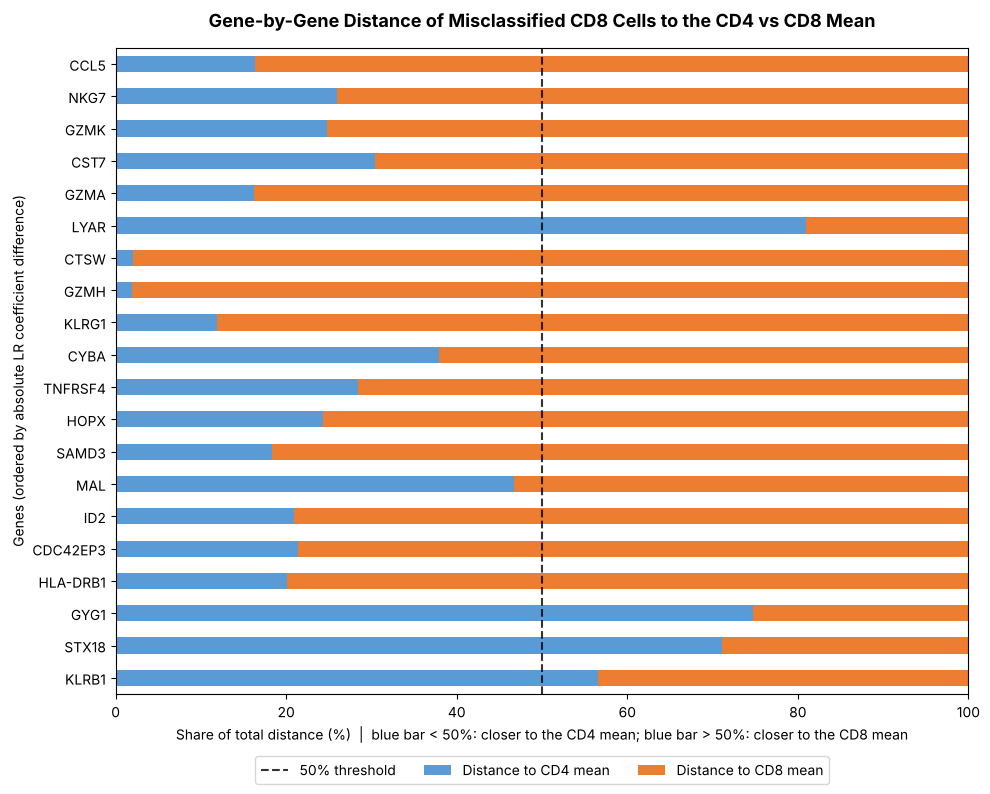

In [39]:
# For each gene: is the mean expression of the misclassified CD8 cells closer to the CD4 mean or to the CD8 mean?
expr_cd4 = group_means.loc["Correct CD4"]
expr_mis = group_means.loc["Misclassified CD8 (as CD4)"]
expr_cd8 = group_means.loc["Correct CD8"]

dist_to_cd4 = (expr_mis - expr_cd4).abs()
dist_to_cd8 = (expr_mis - expr_cd8).abs()
total_dist = dist_to_cd4 + dist_to_cd8 + 1e-6

# Share of the total distance that lies on the CD4 side / on the CD8 side
distance_share = pd.DataFrame({
    "Distance to CD4 mean (%)": dist_to_cd4 / total_dist * 100,
    "Distance to CD8 mean (%)": dist_to_cd8 / total_dist * 100,
}).iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 8))
distance_share["Distance to CD4 mean (%)"].plot(kind="barh", color="#5B9BD5", ax=ax, label="Distance to CD4 mean")
distance_share["Distance to CD8 mean (%)"].plot(kind="barh", color="#ED7D31", left=distance_share["Distance to CD4 mean (%)"], ax=ax, label="Distance to CD8 mean")
ax.axvline(50, color="black", linestyle="--", linewidth=1.5, alpha=0.8, label="50% threshold")
ax.set_title("Gene-by-Gene Distance of Misclassified CD8 Cells to the CD4 vs CD8 Mean", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Share of total distance (%)  |  blue bar < 50%: closer to the CD4 mean; blue bar > 50%: closer to the CD8 mean")
ax.set_ylabel("Genes (ordered by absolute LR coefficient difference)")
ax.set_xlim(0, 100)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=True)
plt.tight_layout()
plt.show()

**Interpretation.** For most of the top genes the misclassified cells are closer to the CD4 average. The exceptions are `LYAR`, `GYG1`, `STX18` and `KLRB1`, where they are closer to (or even above) the CD8 average. The misclassified cells are therefore not a uniform group, and averaging over them hides cell-to-cell variation.

#### 4.4.4 Individual cells

First, the predicted probabilities of the tuned Logistic Regression for the 10 commonly misclassified CD8 cells. The cell with the strongest preference for CD4 is selected as a focus cell for a detailed explanation.

In [40]:
# Predicted probabilities of the tuned LR model for the commonly misclassified CD8 cells
X_misclassified = X_test_reduced.loc[misclassified_idx]
probabilities = best_model.predict_proba(X_misclassified)
classes_list = list(best_model.classes_)

p_cd4 = probabilities[:, classes_list.index("CD4 T cells")]
p_cd8 = probabilities[:, classes_list.index("CD8 T cells")]

prob_table = pd.DataFrame({
    "Cell Test Index": misclassified_idx,
    "True Label": "CD8 T cells",
    "P(CD4)": p_cd4,
    "P(CD8)": p_cd8,
    "P(CD8) - P(CD4)": p_cd8 - p_cd4,
})
display(prob_table.round(3))

# The cell with the strongest preference for CD4 is analysed in detail below
focus_cell = int(prob_table.loc[prob_table["P(CD8) - P(CD4)"].idxmin(), "Cell Test Index"])
print("Focus cell (strongest CD4 preference):", focus_cell)

,Cell Test Index,True Label,P(CD4),P(CD8),P(CD8) - P(CD4)
0,41,CD8 T cells,0.760,0.219,-0.541
1,71,CD8 T cells,0.874,0.046,-0.828
2,76,CD8 T cells,0.770,0.197,-0.573
3,191,CD8 T cells,0.871,0.092,-0.780
4,345,CD8 T cells,0.762,0.196,-0.566
5,360,CD8 T cells,0.805,0.143,-0.663
6,399,CD8 T cells,0.841,0.139,-0.702
7,431,CD8 T cells,0.543,0.426,-0.117
8,459,CD8 T cells,0.605,0.371,-0.235
9,478,CD8 T cells,0.642,0.345,-0.297


Focus cell (strongest CD4 preference): 71


**Interpretation.** Most cells receive P(CD4) between 0.54 and 0.87 and are far from the decision boundary (cell 71: P(CD4) = 0.874, P(CD8) = 0.046). Cells 431, 459 and 478 are borderline (P(CD8) between 0.35 and 0.43), so they are uncertain rather than confidently wrong.

The heatmap places each of the 10 misclassified cells next to the average correct CD4 and CD8 profile.

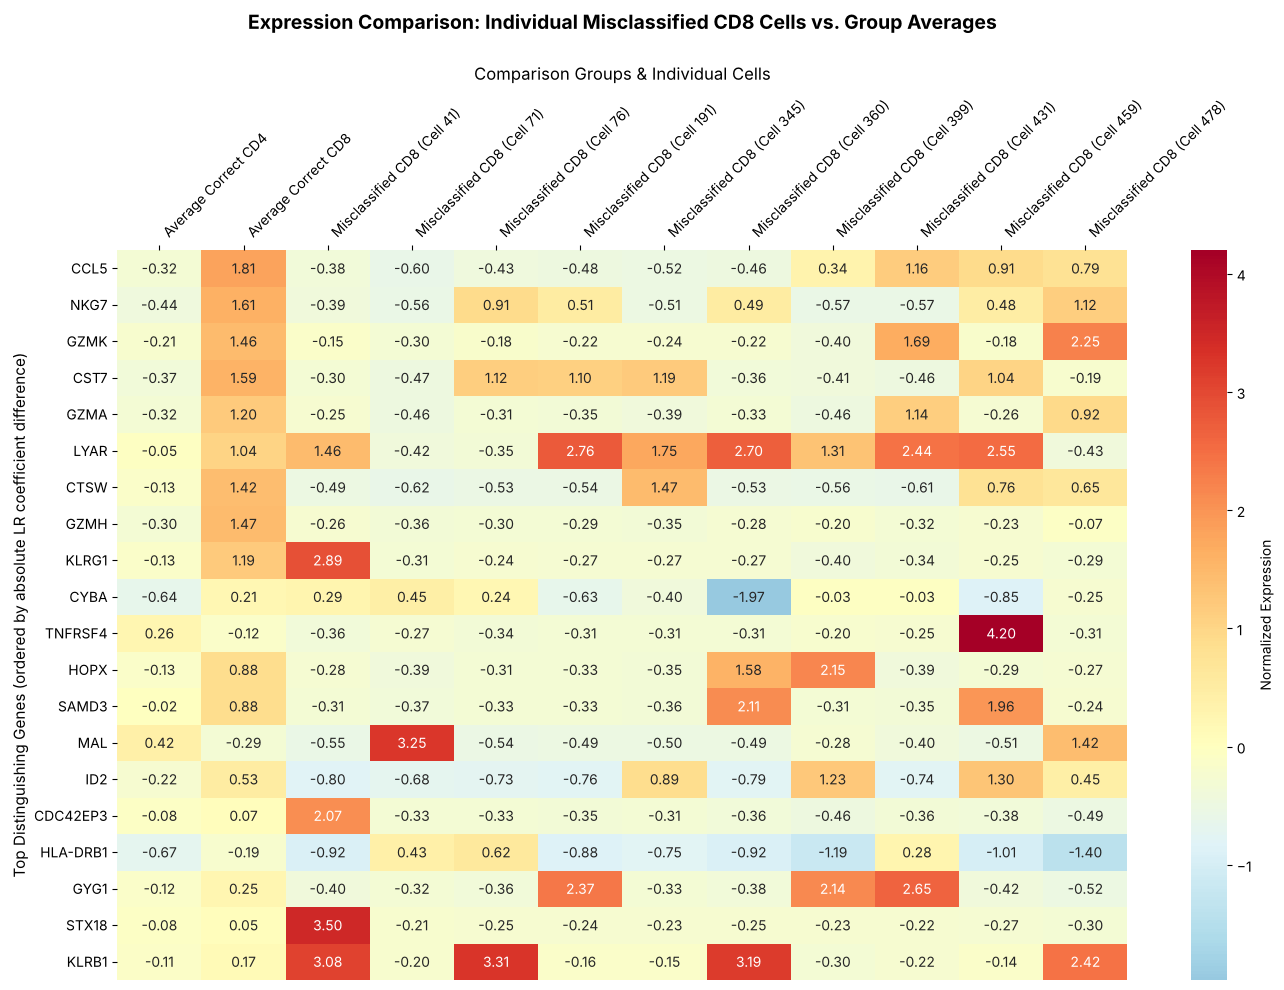

In [41]:
# Expression of each misclassified cell next to the average correct CD4 / CD8 profile
misclassified_expr = X_test_df.loc[misclassified_idx, top_diff_genes].copy()
misclassified_expr.index = [f"Misclassified CD8 (Cell {idx})" for idx in misclassified_expr.index]

group_avg = pd.DataFrame({
    "Average Correct CD4": plot_df[plot_df["Group"] == "Correct CD4"][top_diff_genes].mean(),
    "Average Correct CD8": plot_df[plot_df["Group"] == "Correct CD8"][top_diff_genes].mean(),
}).T

comparison_df = pd.concat([group_avg, misclassified_expr])

plt.figure(figsize=(14, 10))
ax = sns.heatmap(
    comparison_df.T,
    cmap="RdYlBu_r",
    center=0,
    annot=True,
    fmt=".2f",
    cbar_kws={"label": "Normalized Expression"},
)
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")
plt.title("Expression Comparison: Individual Misclassified CD8 Cells vs. Group Averages", fontsize=14, fontweight="bold", pad=25)
plt.xlabel("Comparison Groups & Individual Cells", fontsize=12, labelpad=12)
plt.ylabel("Top Distinguishing Genes (ordered by absolute LR coefficient difference)", fontsize=11)
plt.xticks(rotation=45, ha="left")
plt.tight_layout()
plt.show()

**Interpretation.** Several misclassified cells, particularly cell 71, show low expression of `CCL5`, `NKG7`, `GZMK`, `CST7` and `GZMA` compared with correct CD8 cells, and are closer to the average CD4 profile. Others have high `LYAR`, `GYG1`, `HOPX` or `KLRB1`, which confirms the heterogeneity among the misclassified cells. Expression differences alone cannot show how each gene influenced the model's decision, which is the topic of the next step.

#### 4.4.5 Local explanation of the model's decision

For each gene `j`, the contribution to the CD8-versus-CD4 decision score of a cell is

$$C_j = x_j \times (\beta_{CD8,j} - \beta_{CD4,j})$$

where `x_j` is the standardized expression. Negative contributions push the prediction towards CD4, positive contributions towards CD8. The heatmap shows this for the 20 key genes in all 10 misclassified cells.

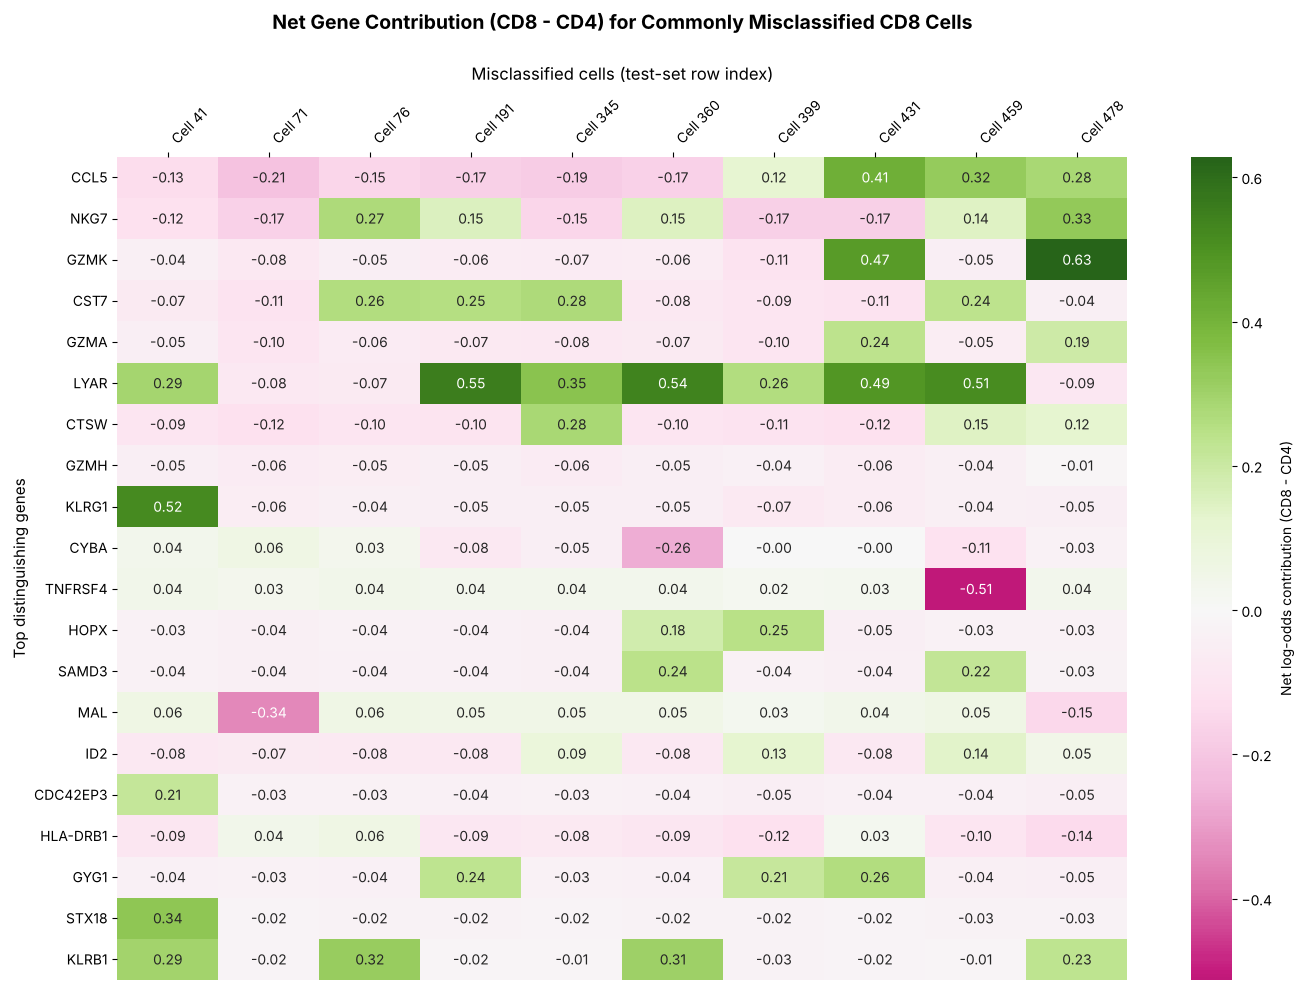

In [42]:
# Contribution of gene j to the CD8-vs-CD4 log-odds for each misclassified cell:
#   C_j = expression_j * (beta_CD8,j - beta_CD4,j)
# Positive values push the prediction towards CD8, negative values towards CD4.
net_contribution = X_misclassified[top_diff_genes].multiply(coef_comparison.loc[top_diff_genes, "difference"], axis=1)
net_contribution.index = [f"Cell {idx}" for idx in net_contribution.index]

plt.figure(figsize=(14, 10))
ax = sns.heatmap(
    net_contribution.T,
    cmap="PiYG",
    center=0,
    annot=True,
    fmt=".2f",
    cbar_kws={"label": "Net log-odds contribution (CD8 - CD4)"},
)
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")
plt.title("Net Gene Contribution (CD8 - CD4) for Commonly Misclassified CD8 Cells", fontsize=14, fontweight="bold", pad=25)
plt.xlabel("Misclassified cells (test-set row index)", fontsize=12, labelpad=12)
plt.ylabel("Top distinguishing genes", fontsize=11)
plt.xticks(rotation=45, ha="left")
plt.tight_layout()
plt.show()

**Interpretation.** Cytotoxic genes (`CCL5`, `NKG7`, `GZMK`, ...) contribute negatively in most of these cells, because their expression is low or negative while their weights favour CD8. Contributions from the remaining genes differ from cell to cell, so there is no single common reason for the errors.

Next, the focus cell (cell 71) is analysed using **all 997 genes**: the 15 strongest contributions in each direction.

Cell 71: genes analysed = 997

Top 15 genes pulling the cell towards CD4 (strongest first):


,Expression,Weight_Difference (CD8 - CD4),Net_Contribution (CD8 - CD4)
index,,,
MAL,3.246420,-0.105663,-0.343027
CCL5,-0.597144,0.357895,-0.213715
NT5C3A,5.736468,-0.032215,-0.184802
AQP3,1.947657,-0.090655,-0.176565
NKG7,-0.564654,0.298962,-0.168810
BACH1,7.177536,-0.020290,-0.145633
CCDC66,4.403924,-0.029600,-0.130357
CTSW,-0.615957,0.192203,-0.118389
CST7,-0.474891,0.231117,-0.109755


Top 15 genes pulling the cell towards CD8 (strongest first):


,Expression,Weight_Difference (CD8 - CD4),Net_Contribution (CD8 - CD4)
index,,,
LRBA,4.188249,0.079608,0.333417
SLC25A11,2.627272,0.063065,0.165688
WTAP,2.094860,0.067500,0.141403
DYNLT1,3.400040,0.037726,0.128270
RRS1,5.492162,0.022134,0.121562
WDR45,3.375323,0.032515,0.109749
RPL22L1,1.944871,0.049368,0.096015
TCEAL4,4.444997,0.021264,0.094517
TAF12,2.429020,0.036482,0.088616


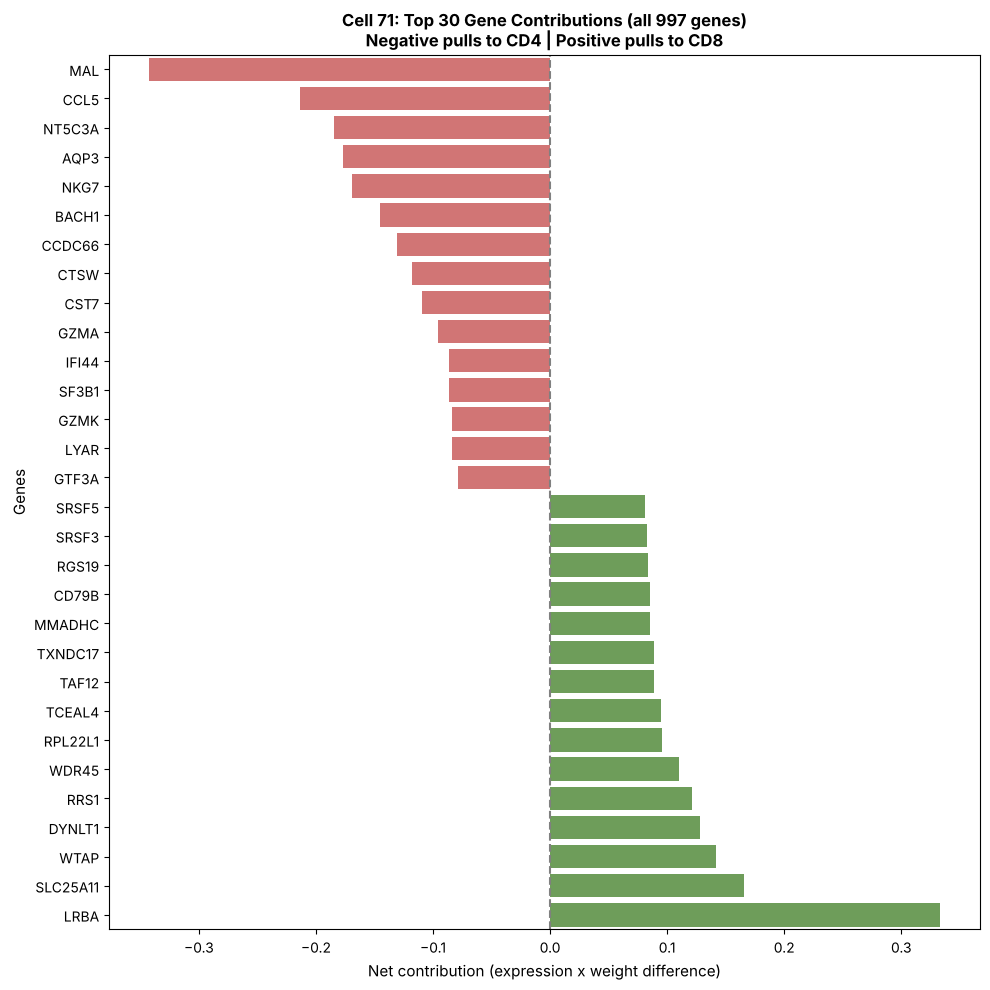

In [43]:
# Contribution of all 997 genes for the focus cell
focus_expr = X_test_reduced.loc[focus_cell]
focus_contrib = (focus_expr * coef_comparison["difference"])

contrib_all_df = pd.DataFrame({
    "Expression": focus_expr,
    "Weight_Difference (CD8 - CD4)": coef_comparison["difference"],
    "Net_Contribution (CD8 - CD4)": focus_contrib,
}).sort_values("Net_Contribution (CD8 - CD4)")

print(f"Cell {focus_cell}: genes analysed = {len(contrib_all_df)}")

print("\nTop 15 genes pulling the cell towards CD4 (strongest first):")
display(contrib_all_df.head(15))

print("Top 15 genes pulling the cell towards CD8 (strongest first):")
display(contrib_all_df.tail(15).iloc[::-1])

# Bar plot: 15 strongest negative + 15 strongest positive contributions
plot_data = pd.concat([contrib_all_df.head(15), contrib_all_df.tail(15)])
bar_colors = ["#E06666" if val < 0 else "#6AA84F" for val in plot_data["Net_Contribution (CD8 - CD4)"]]

plt.figure(figsize=(10, 10))
sns.barplot(x=plot_data["Net_Contribution (CD8 - CD4)"], y=plot_data.index,
            hue=plot_data.index, palette=bar_colors, legend=False)
plt.axvline(0, color="grey", linestyle="--", linewidth=1.5)
plt.title(f"Cell {focus_cell}: Top 30 Gene Contributions (all 997 genes)\nNegative pulls to CD4 | Positive pulls to CD8", fontsize=12, fontweight="bold")
plt.xlabel("Net contribution (expression x weight difference)", fontsize=11)
plt.ylabel("Genes", fontsize=11)
plt.tight_layout()
plt.show()

**Interpretation.** Two patterns push cell 71 towards CD4:

1. **Low expression of CD8-associated cytotoxic genes** (`CCL5`, `NKG7`, `CTSW`, `CST7`, `GZMA`, `GZMK`). They have positive weights for CD8, but their expression in this cell is negative, which gives negative contributions.
2. **High expression of genes with CD4-favouring weights** (`MAL` +3.25, `NT5C3A`, `AQP3`), which add to the push towards CD4.

Some genes do support CD8 (e.g. `LRBA`, +0.333, almost cancelling `MAL`, -0.343), so the final decision is the sum of many small contributions, not of a single dominant gene. Genes with the largest coefficient differences are not always the genes with the largest local contribution, because the contribution depends on both the weight and the expression value in that cell.

#### 4.4.6 Validation of the decomposition

To make sure the explanation is exact, we check that (1) the decision scores can be rebuilt from `expression x coefficient + intercept`, (2) the softmax of the 8 scores reproduces the predicted probabilities and (3) the gene contributions plus the intercept difference add up to the CD8-versus-CD4 score difference.

In [44]:
# Check 1: can the decision scores be rebuilt from expression x coefficient + intercept?
classes_list = list(best_model.classes_)
focus_row = X_test_reduced.loc[focus_cell].values.reshape(1, -1)

manual_scores = np.array([
    np.dot(X_test_reduced.loc[focus_cell], coef_df.loc[c]) + best_model.intercept_[i]
    for i, c in enumerate(classes_list)
])
model_scores = best_model.decision_function(focus_row)[0]

i4, i8 = classes_list.index("CD4 T cells"), classes_list.index("CD8 T cells")
validation_df = pd.DataFrame({
    "Metric": ["CD4 T cells score", "CD8 T cells score", "Score difference (CD8 - CD4)"],
    "Manual reconstruction": [manual_scores[i4], manual_scores[i8], manual_scores[i8] - manual_scores[i4]],
    "Model output": [model_scores[i4], model_scores[i8], model_scores[i8] - model_scores[i4]],
})
validation_df["Absolute error"] = (validation_df["Manual reconstruction"] - validation_df["Model output"]).abs()
display(validation_df)

# Check 2: do the softmax of the 8 scores reproduce predict_proba?
exp_scores = np.exp(manual_scores - manual_scores.max())
softmax_probs = exp_scores / exp_scores.sum()
model_probs = best_model.predict_proba(focus_row)[0]

display(pd.DataFrame({
    "Cell type": classes_list,
    "Reconstructed prob (%)": np.round(softmax_probs * 100, 2),
    "Model prob (%)": np.round(model_probs * 100, 2),
}))

,Metric,Manual reconstruction,Model output,Absolute error
0,CD4 T cells score,3.997057,3.997057,8.881784e-16
1,CD8 T cells score,1.047438,1.047438,6.661338e-16
2,Score difference (CD8 - CD4),-2.949618,-2.949618,1.776357e-15


,Cell type,Reconstructed prob (%),Model prob (%)
0,B cells,4.09,4.09
1,CD14+ Monocytes,1.68,1.68
2,CD4 T cells,87.40,87.40
3,CD8 T cells,4.58,4.58
4,Dendritic cells,1.00,1.00
5,FCGR3A+ Monocytes,0.98,0.98
6,Megakaryocytes,0.10,0.10
7,NK cells,0.16,0.16


In [45]:
# Check 3: the per-gene contributions plus the intercept difference add up to the score difference
intercept_difference = best_model.intercept_[i8] - best_model.intercept_[i4]
contribution_sum = focus_contrib.sum()
reconstructed_difference = intercept_difference + contribution_sum
model_difference = model_scores[i8] - model_scores[i4]

print("Number of genes:", len(focus_contrib))
print("Intercept difference (CD8 - CD4):", round(intercept_difference, 4))
print("Sum of gene contributions:       ", round(contribution_sum, 4))
print("Reconstructed score difference:  ", round(reconstructed_difference, 4))
print("Model score difference:          ", round(model_difference, 4))
print("Absolute error:                  ", abs(reconstructed_difference - model_difference))

Number of genes: 997
Intercept difference (CD8 - CD4): -1.3399
Sum of gene contributions:        -1.6097
Reconstructed score difference:   -2.9496
Model score difference:           -2.9496
Absolute error:                   4.440892098500626e-16


**Interpretation.** All three checks match the model output up to numerical precision (absolute error around 1e-15). For cell 71 the CD8-minus-CD4 score is -2.95, composed of an intercept difference of -1.34 and a summed gene contribution of -1.61. The gene-level explanation is therefore an exact description of the model's decision.

*Limitation:* the analysis explains the Logistic Regression model, not the biology. It does not prove that these genes are biologically responsible for the misclassification.

### 4.5 Summary of RQ1

- Classical models classify PBMC cell types well: the tuned Logistic Regression reaches test accuracy 0.943 and macro F1 0.925 with 997 genes; SVM is close, tree-based models are weaker.
- Feature selection and correlation filtering reduce the feature set by about half without loss of performance.
- **CD4 and CD8 T cells are the main source of error** for every model. About 16% of CD8 cells are misclassified as CD4 by all four models, and gene-level analysis links this to weaker cytotoxic gene expression in these cells.

These results are the baseline for RQ2: can a biologically informed, lower-dimensional representation keep this performance?

## 5. RQ2 - Pathway-level feature representation

Instead of 997 individual genes, each cell is now described by a small number of **pathway scores**. For each pathway, the genes present in the dataset are identified; pathways with fewer than five matched genes are excluded. The pathway score of a cell is the **mean standardized expression of its matched genes**. A Logistic Regression is then trained on these scores, using the same cells, split and cross-validation folds as before.

*Important:* these scores summarize gene expression of a pathway's genes; they are not direct measurements of pathway activity.

### 5.1 Hallmark gene sets (exploratory baseline)

The 50 MSigDB Hallmark gene sets are a compact, low-redundancy collection of biological processes, so they were a practical first choice. They are not designed to separate immune cell subtypes, which is a limitation of this first attempt.

In [46]:
import gseapy as gp

# Hallmark gene sets (MSigDB, via Enrichr) - requires internet access
hallmark = gp.get_library(name="MSigDB_Hallmark_2020", organism="Human")
print("Number of Hallmark gene sets:", len(hallmark))

Number of Hallmark gene sets: 50


In [47]:
# How many genes of each Hallmark set are present in our 1,838-gene dataset?
dataset_genes = set(adata.var_names)

coverage_results = []
for pathway, genes in hallmark.items():
    pathway_genes = set(genes)
    matched_genes = pathway_genes & dataset_genes
    coverage_results.append({
        "Pathway": pathway,
        "Original_gene_count": len(pathway_genes),
        "Matched_gene_count": len(matched_genes),
        "Coverage": len(matched_genes) / len(pathway_genes),
    })

coverage_df = pd.DataFrame(coverage_results)

print("Total pathways:", len(coverage_df))
print("Pathways with at least 5 matched genes:", (coverage_df["Matched_gene_count"] >= 5).sum())

display(coverage_df.sort_values("Matched_gene_count", ascending=False).head(10))

Total pathways: 50
Pathways with at least 5 matched genes: 45


,Pathway,Original_gene_count,Matched_gene_count,Coverage
18,Interferon Gamma Response,200,45,0.22500
45,Allograft Rejection,200,42,0.21000
42,IL-2/STAT5 Signaling,199,39,0.19598
22,Complement,200,38,0.19000
27,Myc Targets V1,200,38,0.19000
0,TNF-alpha Signaling via NF-kB,200,36,0.18000
11,Adipogenesis,200,30,0.15000
33,Oxidative Phosphorylation,200,28,0.14000
7,DNA Repair,150,27,0.18000
25,mTORC1 Signaling,200,27,0.13500


**Interpretation.** 45 of 50 Hallmark sets have at least 5 genes in the 1,838-gene dataset. Coverage is low (e.g. 45 of 200 genes for *Interferon Gamma Response*), because the dataset contains only highly variable genes.

Pathway scores are computed as described above.

In [48]:
# Dense gene-expression table (cells x genes) with cell barcodes as index
X_dense = adata.X.toarray() if sparse.issparse(adata.X) else adata.X
X_gene = pd.DataFrame(X_dense, index=adata.obs_names, columns=adata.var_names)

# Pathway score = mean standardized expression of the matched genes (pathways with >= 5 matched genes only)
pathway_scores = {}
pathway_coverage = []

for pathway, genes in hallmark.items():
    matched_genes = list(set(genes) & set(X_gene.columns))
    if len(matched_genes) >= 5:
        pathway_scores[pathway] = X_gene[matched_genes].mean(axis=1)
        pathway_coverage.append({
            "Pathway": pathway,
            "Matched_genes": len(matched_genes),
            "Original_genes": len(set(genes)),
            "Coverage": len(matched_genes) / len(set(genes)),
        })

X_pathway = pd.DataFrame(pathway_scores, index=X_gene.index)
coverage_df = pd.DataFrame(pathway_coverage)

print("Gene-level shape:", X_gene.shape)
print("Pathway-level shape:", X_pathway.shape)
print("Median pathway coverage:", coverage_df["Coverage"].median())

Gene-level shape: (2638, 1838)
Pathway-level shape: (2638, 45)
Median pathway coverage: 0.12658227848101267


In [49]:
print("Missing pathway scores:", X_pathway.isna().sum().sum())

print("\nPathway score summary:")
display(X_pathway.describe().T[["mean", "std", "min", "max"]])

print("\nPathways with the fewest matched genes:")
display(coverage_df.sort_values("Matched_genes").head(10))

Missing pathway scores: 0

Pathway score summary:


,mean,std,min,max
TNF-alpha Signaling via NF-kB,-0.004297,0.183329,-0.415599,1.177103
Hypoxia,-0.002107,0.237533,-0.373914,1.376797
Cholesterol Homeostasis,-0.001507,0.305335,-0.644049,1.918554
Mitotic Spindle,-0.004384,0.204482,-0.421077,1.073911
Wnt-beta Catenin Signaling,-0.003359,0.322096,-0.415190,2.324468
TGF-beta Signaling,-0.005539,0.277440,-0.446917,1.436543
IL-6/JAK/STAT3 Signaling,-0.006802,0.257574,-0.469301,2.135831
DNA Repair,-0.001479,0.194430,-0.492171,0.952105
G2-M Checkpoint,-0.002044,0.244678,-0.391183,2.135052
Apoptosis,-0.001933,0.243405,-0.526480,1.433923



Pathways with the fewest matched genes:


,Pathway,Matched_genes,Original_genes,Coverage
32,Reactive Oxygen Species Pathway,5,49,0.102041
25,Myc Targets V2,6,58,0.103448
35,UV Response Dn,9,144,0.062500
4,Wnt-beta Catenin Signaling,9,42,0.214286
44,KRAS Signaling Dn,9,200,0.045000
11,Estrogen Response Early,10,200,0.050000
5,TGF-beta Signaling,11,54,0.203704
15,Protein Secretion,11,96,0.114583
40,Pperoxisome,11,104,0.105769
2,Cholesterol Homeostasis,12,74,0.162162


**Interpretation.** The gene-level matrix (2,638 x 1,838) is reduced to 45 pathway features. The median coverage of the retained sets is about 13%, so each pathway score is based on only a small part of the pathway's genes. The score summary shows no missing values.

#### Logistic Regression on Hallmark scores

Scaling and Logistic Regression are fitted inside each CV fold. This baseline uses no class weights and default regularization.

In [50]:
# Same cells as the gene-level analysis: rows are selected with the shared train_idx / test_idx
assert X_pathway.index.equals(adata.obs_names)
X_train_pathway = X_pathway.iloc[train_idx]
X_test_pathway = X_pathway.iloc[test_idx]

# Scaling and LR are fitted separately inside each CV fold (no information leaks from held-out folds)
pathway_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(max_iter=2000, random_state=42)),
])

cv_results = cross_validate(
    pathway_pipeline,
    X_train_pathway,
    y_train,
    cv=kfold,
    scoring={"accuracy": "accuracy", "macro_f1": "f1_macro", "weighted_f1": "f1_weighted"},
)

print("5-fold CV results")
print(f"Accuracy:    {cv_results['test_accuracy'].mean():.4f} +/- {cv_results['test_accuracy'].std():.4f}")
print(f"Macro F1:    {cv_results['test_macro_f1'].mean():.4f} +/- {cv_results['test_macro_f1'].std():.4f}")
print(f"Weighted F1: {cv_results['test_weighted_f1'].mean():.4f} +/- {cv_results['test_weighted_f1'].std():.4f}")

5-fold CV results
Accuracy:  0.7602 +/- 0.0157
Macro F1:  0.6523 +/- 0.0414
Weighted F1: 0.7526 +/- 0.0150


In [51]:
pathway_pipeline.fit(X_train_pathway, y_train)
pathway_pred = pathway_pipeline.predict(X_test_pathway)

print("Test Accuracy:", accuracy_score(y_test, pathway_pred))
print("Test Macro F1:", f1_score(y_test, pathway_pred, average="macro"))
print("\nClassification Report:")
print(classification_report(y_test, pathway_pred, zero_division=0))

Test Accuracy: 0.7556818181818182
Test Macro F1: 0.6202594918616893

Classification Report:
                   precision    recall  f1-score   support

          B cells       0.81      0.67      0.73        69
  CD14+ Monocytes       0.76      0.89      0.82        96
      CD4 T cells       0.81      0.90      0.85       229
      CD8 T cells       0.57      0.48      0.52        63
  Dendritic cells       0.33      0.14      0.20         7
FCGR3A+ Monocytes       0.43      0.30      0.35        30
   Megakaryocytes       1.00      0.67      0.80         3
         NK cells       0.74      0.65      0.69        31

         accuracy                           0.76       528
        macro avg       0.68      0.59      0.62       528
     weighted avg       0.74      0.76      0.74       528



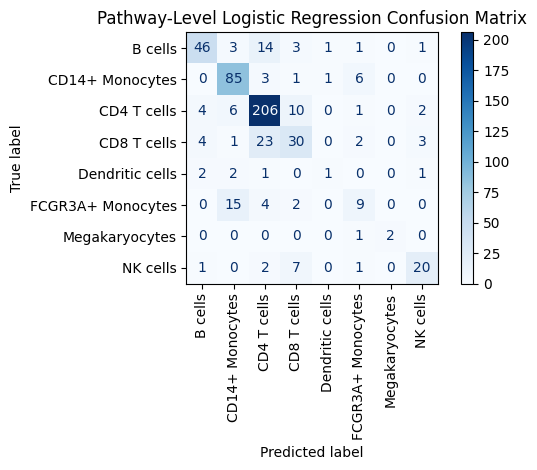

In [52]:
ConfusionMatrixDisplay.from_predictions(y_test, pathway_pred, xticks_rotation=90, cmap="Blues")
plt.title("Hallmark Pathway-Level Logistic Regression")
plt.tight_layout()
plt.show()

**Interpretation.** Cross-validated macro F1 is only 0.652 (accuracy 0.760), and on the test set accuracy is 0.756 and macro F1 0.620. CD8 T cells (F1 0.52), Dendritic cells (0.20) and FCGR3A+ monocytes (0.35) are very poorly recognised. Generic Hallmark processes (e.g. hypoxia, Wnt signalling) are not specific to the immune-cell subtypes in this dataset, so they provide much less information than the gene-level features. This motivates using a gene-set collection that is focused on the immune system.

### 5.2 Reactome immune-system pathways

Reactome describes curated biological pathways with many immune-specific entries. First, the coverage of Hallmark and Reactome in our dataset is compared.

In [53]:
# Compare gene-set coverage of Hallmark and Reactome in our dataset
dataset_genes = set(adata.var_names)

libraries = {"Hallmark": "MSigDB_Hallmark_2020", "Reactome": "Reactome_2022"}
results = []

for name, library in libraries.items():
    gene_sets = gp.get_library(name=library, organism="Human")
    for pathway, genes in gene_sets.items():
        genes = set(genes)
        overlap = genes & dataset_genes
        results.append({
            "Database": name,
            "Pathway": pathway,
            "Total_genes": len(genes),
            "Matched_genes": len(overlap),
            "Coverage": len(overlap) / len(genes) if len(genes) > 0 else 0,
        })

coverage_all = pd.DataFrame(results)
summary = coverage_all.groupby("Database").agg(
    Total_pathways=("Pathway", "count"),
    Median_matched_genes=("Matched_genes", "median"),
    Median_coverage=("Coverage", "median"),
    Pathways_with_5_genes=("Matched_genes", lambda x: (x >= 5).sum()),
)
display(summary)

,Total_pathways,Median_matched_genes,Median_coverage,Pathways_with_5_genes
Database,,,,
Hallmark,50,17.0,0.124094,45
Reactome,1816,3.0,0.110703,649


**Interpretation.** Reactome has many more pathways (1,816) than Hallmark (50), but most are small, with a median of 3 matched genes. Only 649 Reactome pathways have at least 5 matched genes in our data, so a selection is needed.

Immune-related Reactome pathways are selected by name using a keyword list (immune, interferon, cytokine, antigen, interleukin, ...).

In [54]:
# Select immune-related Reactome pathways by keyword
reactome_library = gp.get_library(name="Reactome_2022", organism="Human")

immune_keywords = [
    "immune", "interferon", "cytokine", "antigen",
    "interleukin", "toll-like", "nod-like", "b_cell",
    "t_cell", "chemokine", "tcr", "bcr", "neutrophil",
    "macrophage", "mast_cell", "complement_cascade",
    "class_i_mhc", "class_ii_mhc", "pd-1",
]

immune_subpathways = []
for pathway, genes in reactome_library.items():
    if any(keyword in pathway.lower() for keyword in immune_keywords):
        matched_genes = set(genes) & dataset_genes
        immune_subpathways.append({
            "Pathway": pathway,
            "Total_Genes_in_DB": len(genes),
            "Matched_Genes": len(matched_genes),
            "Coverage": len(matched_genes) / len(genes) if len(genes) > 0 else 0,
            "Matched_Gene_List": list(matched_genes),
        })

immune_subpathways_df = pd.DataFrame(immune_subpathways)

print(f"Filtered out {len(immune_subpathways_df)} immune-related subpathways from Reactome_2022.")
print(f"There are {(immune_subpathways_df['Matched_Genes'] >= 5).sum()} pathways containing at least 5 matched genes.")

display(immune_subpathways_df.sort_values("Matched_Genes", ascending=False).head(10))

Filtered out 66 immune-related subpathways from Reactome_2022.
There are 30 pathways containing at least 5 matched genes.


,Pathway,Total_Genes_in_DB,Matched_Genes,Coverage,Matched_Gene_List
18,Immune System R-HSA-168256,1943,286,0.147195,"[VAPA, RBCK1, GLB1, HLA-DRB1, FBXO7, CD274, ML..."
19,Innate Immune System R-HSA-168249,1035,157,0.151691,"[VAPA, GLB1, FCN1, MLEC, FOLR3, ZBP1, DYNLT1, ..."
1,Adaptive Immune System R-HSA-1280218,733,130,0.177353,"[RBCK1, CD274, HLA-DRB1, FBXO7, KIR2DL3, SEC31..."
11,Cytokine Signaling In Immune System R-HSA-1280215,702,96,0.136752,"[HLA-DRB1, TRIM8, RELB, MAP3K8, F13A1, HLA-DPA..."
51,Neutrophil Degranulation R-HSA-6798695,468,80,0.170940,"[VAPA, GLB1, FCN1, MLEC, FOLR3, DYNLT1, FCAR, ..."
8,Class I MHC Mediated Antigen Processing And Pr...,378,61,0.161376,"[RBCK1, PSMD14, FBXO7, PSMA7, SEC31A, LONRF1, ..."
62,Signaling By Interleukins R-HSA-449147,453,58,0.128035,"[PIK3R1, IL27RA, CISH, PPP2R1B, MAP2K7, MAP3K7..."
5,Antigen Processing: Ubiquitination And Proteas...,307,48,0.156352,"[RBCK1, PSMD14, FBXO7, PSMA7, LONRF1, TRIM69, ..."
20,Interferon Signaling R-HSA-913531,200,29,0.145000,"[HLA-DRB1, TRIM8, IFI27, IFI35, IFI30, HLA-DPA..."
63,Signaling By B Cell Receptor (BCR) R-HSA-983705,109,25,0.229358,"[SH3KBP1, PIK3R1, MAP3K7, PSMD14, PSMA7, MALT1..."


**Interpretation.** 66 immune-related pathways were found and 30 of them have at least 5 matched genes. These include broad parent pathways (e.g. *Immune System*, *Innate Immune System*, *Adaptive Immune System*) and more specific ones (e.g. *TCR Signaling*, *Interferon Signaling*). Parent and child pathways share many genes, so some of the 30 features are nested and correlated.

Pathway scores are calculated for the 30 selected pathways in the same way as before.

In [55]:
# Pathway score = mean standardized expression of the matched genes (pathways with >= 5 matched genes only)
reactome_scores_dict = {}
reactome_coverage_list = []

for _, row in immune_subpathways_df.iterrows():
    matched_genes = row["Matched_Gene_List"]
    if len(matched_genes) >= 5:
        reactome_scores_dict[row["Pathway"]] = X_gene[matched_genes].mean(axis=1)
        reactome_coverage_list.append({
            "Pathway": row["Pathway"],
            "Matched_genes": len(matched_genes),
            "Original_genes": row["Total_Genes_in_DB"],
            "Coverage": len(matched_genes) / row["Total_Genes_in_DB"],
        })

X_reactome_pathway = pd.DataFrame(reactome_scores_dict, index=X_gene.index)
reactome_coverage_df = pd.DataFrame(reactome_coverage_list)

print("Gene-level feature shape:", X_gene.shape)
print("Reactome pathway-level feature shape:", X_reactome_pathway.shape)
print("Median pathway coverage:", reactome_coverage_df["Coverage"].median())

display(X_reactome_pathway.head())

=== Reactome Immune-Related Pathways Score Construction ===
Gene-level feature shape: (2638, 1838)
Reactome Pathway-level feature shape: (2638, 30)
Number of selected pathways (>= 5 genes): 30
Median pathway coverage: 0.1731893837156995


,ADORA2B Mediated Anti-Inflammatory Cytokine Production R-HSA-9660821,Adaptive Immune System R-HSA-1280218,Antigen Activates B Cell Receptor Leading To Second Messenger Generation R-HSA-983695,Antigen processing-Cross Presentation R-HSA-1236975,Antigen Processing: Ubiquitination And Proteasome Degradation R-HSA-983168,Chemokine Receptors Bind Chemokines R-HSA-380108,Class I MHC Mediated Antigen Processing And Presentation R-HSA-983169,Cross-presentation Of Soluble Exogenous Antigens (Endosomes) R-HSA-1236978,Cytokine Signaling In Immune System R-HSA-1280215,DDX58/IFIH1-mediated Induction Of Interferon-Alpha/Beta R-HSA-168928,...,Interleukin-12 Family Signaling R-HSA-447115,Interleukin-17 Signaling R-HSA-448424,Interleukin-4 And Interleukin-13 Signaling R-HSA-6785807,MHC Class II Antigen Presentation R-HSA-2132295,Neutrophil Degranulation R-HSA-6798695,PD-1 Signaling R-HSA-389948,Signaling By Interleukins R-HSA-449147,Signaling By B Cell Receptor (BCR) R-HSA-983705,TCR Signaling R-HSA-202403,Toll-like Receptor Cascades R-HSA-168898
index,,,,,,,,,,,,,,,,,,,,,
AAACATACAACCAC-1,-0.158048,-0.133508,-0.337733,-0.343567,-0.099699,0.020145,-0.139634,-0.463885,-0.186012,-0.068916,...,-0.001975,-0.123657,-0.063562,-0.433446,-0.224832,-0.544486,-0.192351,-0.350121,-0.263240,-0.303902
AAACATTGAGCTAC-1,0.121351,0.114315,0.147589,-0.470634,-0.219221,-0.133829,-0.286325,-0.450319,-0.143041,0.066964,...,-0.041154,0.206425,-0.126490,0.624008,-0.320445,0.384146,-0.166778,-0.063958,0.034257,-0.251165
AAACATTGATCAGC-1,-0.165522,0.038507,-0.096031,0.081205,-0.084984,-0.141901,-0.108113,0.319457,-0.061561,-0.043604,...,-0.224910,-0.152091,0.011239,-0.093095,-0.034539,1.044777,0.002698,0.079129,0.158507,-0.140947
AAACCGTGCTTCCG-1,0.124399,0.068090,-0.320782,0.254447,0.160421,0.077161,0.188462,0.167871,0.100745,0.391966,...,-0.185392,-0.242949,0.119804,0.228621,0.596068,0.503039,0.016540,-0.097978,0.186956,0.201763
AAACCGTGTATGCG-1,-0.141960,0.115154,-0.300922,0.021824,0.104907,0.727381,0.072376,0.223231,-0.000132,-0.454976,...,-0.299797,-0.403126,-0.237574,0.142458,0.043238,-0.016573,0.131358,0.040757,0.095960,-0.191883


In [56]:
print("Missing pathway scores:", X_reactome_pathway.isna().sum().sum())

print("\nPathway score summary:")
display(X_reactome_pathway.describe().T[["mean", "std", "min", "max"]])

print("\nPathways with the fewest matched genes:")
display(reactome_coverage_df.sort_values("Matched_genes").head(10))

Missing pathway scores: 0

Pathway score summary:


,mean,std,min,max
ADORA2B Mediated Anti-Inflammatory Cytokine Production R-HSA-9660821,-0.009753,0.279278,-0.223015,2.332677
Adaptive Immune System R-HSA-1280218,-0.002746,0.118078,-0.303352,0.421040
Antigen Activates B Cell Receptor Leading To Second Messenger Generation R-HSA-983695,-0.000159,0.415003,-0.365739,2.732092
Antigen processing-Cross Presentation R-HSA-1236975,-0.000973,0.265046,-0.686933,1.035999
Antigen Processing: Ubiquitination And Proteasome Degradation R-HSA-983168,-0.002524,0.153998,-0.363815,0.641345
Chemokine Receptors Bind Chemokines R-HSA-380108,-0.008789,0.338343,-0.311438,2.169074
Class I MHC Mediated Antigen Processing And Presentation R-HSA-983169,-0.002353,0.148687,-0.357151,0.656928
Cross-presentation Of Soluble Exogenous Antigens (Endosomes) R-HSA-1236978,-0.000044,0.329226,-0.834258,1.581825
Cytokine Signaling In Immune System R-HSA-1280215,-0.002060,0.130111,-0.325489,0.542909
DDX58/IFIH1-mediated Induction Of Interferon-Alpha/Beta R-HSA-168928,-0.000130,0.285461,-0.599762,1.723924



Pathways with the fewest matched genes:


,Pathway,Matched_genes,Original_genes,Coverage
20,Interleukin-12 Family Signaling R-HSA-447115,6,54,0.111111
25,PD-1 Signaling R-HSA-389948,6,21,0.285714
21,Interleukin-17 Signaling R-HSA-448424,6,69,0.086957
0,ADORA2B Mediated Anti-Inflammatory Cytokine Pr...,10,131,0.076336
2,Antigen Activates B Cell Receptor Leading To S...,10,31,0.322581
22,Interleukin-4 And Interleukin-13 Signaling R-H...,11,107,0.102804
7,Cross-presentation Of Soluble Exogenous Antige...,11,48,0.229167
5,Chemokine Receptors Bind Chemokines R-HSA-380108,12,56,0.214286
19,Interleukin-10 Signaling R-HSA-6783783,12,45,0.266667
15,Interferon Alpha/Beta Signaling R-HSA-909733,13,72,0.180556


**Interpretation.** Each cell is now described by only **30 features** instead of 997 genes. The median coverage of the pathways is 17%, so most scores summarize a small subset of the pathway's genes. There are no missing values, and the scores have mean about 0 and a pathway-specific spread, as expected for averages of standardized genes.

The Reactome score matrix is split with the shared `train_idx` / `test_idx`, so train and test cells are identical to the gene-level analysis.

In [57]:
# Same train/test cells as the gene-level analysis (shared train_idx / test_idx)
X_train_reactome = X_reactome_pathway.iloc[train_idx]
X_test_reactome = X_reactome_pathway.iloc[test_idx]

print("Reactome train shape:", X_train_reactome.shape)
print("Reactome test shape: ", X_test_reactome.shape)

Reactome train shape: (2110, 30)
Reactome test shape:  (528, 30)


### 5.3 Logistic Regression on Reactome scores

The model is built exactly like the gene-level tuned model (standardization, balanced class weights, `C` tuned by 5-fold CV with macro F1).

=== Reactome Pathway-level Tuned Logistic Regression ===
Best parameters_C: 100
Highest score in cross-validation: 0.7423

--- Reactome-level Tuned Test Performance ---
Test Accuracy: 0.7784090909090909
Test Macro F1: 0.6973784883281451
Test Weighted F1: 0.7877321061588796

Classification Report:
                   precision    recall  f1-score   support

          B cells      0.955     0.913     0.933        69
  CD14+ Monocytes      0.865     0.802     0.832        96
      CD4 T cells      0.904     0.821     0.860       229
      CD8 T cells      0.476     0.476     0.476        63
  Dendritic cells      0.222     0.571     0.320         7
FCGR3A+ Monocytes      0.462     0.600     0.522        30
   Megakaryocytes      0.750     1.000     0.857         3
         NK cells      0.683     0.903     0.778        31

         accuracy                          0.778       528
        macro avg      0.665     0.761     0.697       528
     weighted avg      0.804     0.778     0.788   

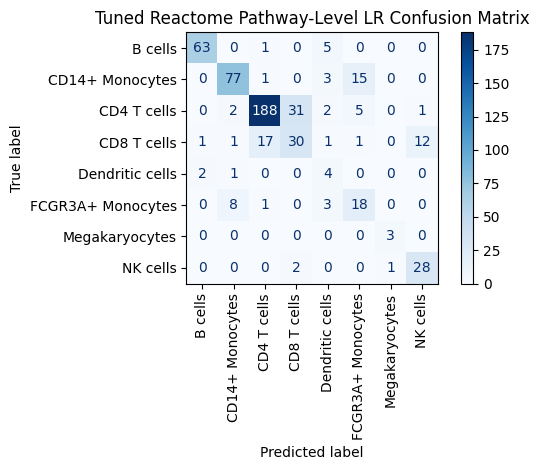

In [58]:
reactome_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lr", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42)),
])

grid_search_reactome = GridSearchCV(
    estimator=reactome_pipeline,
    param_grid={"lr__C": [0.01, 0.1, 1, 10, 100]},
    cv=kfold,
    scoring="f1_macro",
    n_jobs=-1,
)
grid_search_reactome.fit(X_train_reactome, y_train)

print(f"Best C: {grid_search_reactome.best_params_['lr__C']}")
print(f"Best cross-validated Macro F1: {grid_search_reactome.best_score_:.4f}\n")

best_reactome_model = grid_search_reactome.best_estimator_
y_pred_reactome_tuned = best_reactome_model.predict(X_test_reactome)

print("Test Accuracy:", accuracy_score(y_test, y_pred_reactome_tuned))
print("Test Macro F1:", f1_score(y_test, y_pred_reactome_tuned, average="macro"))
print("Test Weighted F1:", f1_score(y_test, y_pred_reactome_tuned, average="weighted"))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_reactome_tuned, digits=3))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_reactome_tuned, xticks_rotation=90, cmap="Blues")
plt.title("Tuned Reactome Pathway-Level LR Confusion Matrix")
plt.tight_layout()
plt.show()

**Interpretation.** The best setting is `C = 100` (weak regularization), which fits since there are only 30 features. Cross-validated macro F1 is 0.742; test accuracy is 0.778 and test macro F1 0.697.

- **Works well:** B cells (F1 0.93), CD14+ monocytes (0.83), Megakaryocytes (0.86, based on 3 cells) and NK cells (0.78), which have clearly distinct immune signatures.
- **Works poorly:** CD8 T cells (F1 0.48), Dendritic cells (0.32) and FCGR3A+ monocytes (0.52).
- **T-cell confusion is much stronger than at gene level:** in the confusion matrix 31 CD4 T cells are predicted as CD8, 17 CD8 cells as CD4 and a further 12 CD8 cells as NK cells. CD14+ and FCGR3A+ monocytes are also confused with each other.

## 6. Comparison, discussion and conclusion

### 6.1 Gene-level vs pathway-level features

| Metric | Gene-level LR | Reactome pathway-level LR |
|---|---:|---:|
| Cross-validation macro F1 | 0.936 | 0.742 |
| Test accuracy | 0.943 | 0.778 |
| Test macro F1 | 0.925 | 0.697 |

The next cell recomputes this table from the fitted models and lists the most frequent errors of both models.

In [ ]:
# Side-by-side comparison of the two feature representations (same cells, same split, same CV)
comparison = pd.DataFrame(
    {
        "Gene-level LR (997 genes)": [
            gene_cv_macro_f1,
            accuracy_score(y_test, y_pred_lr_tuned),
            f1_score(y_test, y_pred_lr_tuned, average="macro"),
        ],
        "Reactome pathway-level LR (30 pathways)": [
            grid_search_reactome.best_score_,
            accuracy_score(y_test, y_pred_reactome_tuned),
            f1_score(y_test, y_pred_reactome_tuned, average="macro"),
        ],
    },
    index=["Cross-validation macro F1", "Test accuracy", "Test macro F1"],
).round(3)
display(comparison)

print("Most frequent errors - gene-level LR:")
display(top_confusions(y_test, y_pred_lr_tuned, n=5))
print("Most frequent errors - Reactome pathway-level LR:")
display(top_confusions(y_test, y_pred_reactome_tuned, n=5))

**Interpretation.** The gene-level model is better on every metric (test macro F1 0.925 vs 0.697). The pathway features still capture major immune lineages, but the simple pathway aggregation does not keep the information needed to separate closely related cell types, in particular CD4 vs CD8 T cells and the two monocyte populations.

### 6.2 Discussion

**Classical machine learning for single-cell classification.** Model comparison, feature selection, hyperparameter tuning and error analysis show that regularized linear models perform best on this dataset. The error analysis was essential: overall accuracy of 94% hides the fact that one specific pair of cell types (CD4/CD8) accounts for most errors.

**Trade-offs between gene-level and pathway-level features.** One possible explanation for the lower pathway-level performance is information loss: averaging genes within a pathway gives all genes the same weight and removes gene-specific information. Because a pathway score is a fixed linear combination of gene values, a Logistic Regression on 30 scores is effectively a constrained version of a Logistic Regression on the genes, with tied weights inside each pathway. The result cannot be attributed to aggregation alone: gene coverage (only about 17% of each pathway's genes are available because the dataset contains highly variable genes only), the keyword-based pathway selection, overlapping parent/child pathways and the much lower dimensionality (30 vs 997 features) may also contribute.

**Biological interpretability.** Pathway-level features are linked to predefined biological processes, which gives a potential interpretability advantage. However, annotated features do not automatically make a model biologically interpretable: the mean score does not represent regulatory interactions, activation/inhibition or the different roles of genes in a pathway, and this project did not test whether pathway-level predictions are easier to explain than gene-level ones. The pathway-level model is therefore an initial exploration, not a fully interpretable biological model. Incorporating biological knowledge into machine learning requires more than grouping genes by pathway.

### 6.3 Conclusion

1. **Gene-level classification (RQ1):** classical models classify PBMC cell types well (best: Logistic Regression, test accuracy 0.943, macro F1 0.925, 997 genes). The remaining difficulty is the separation of CD4 and CD8 T cells.
2. **Pathway-level representation (RQ2):** Reactome immune pathway scores (30 features) reach test accuracy 0.778 and macro F1 0.697. Biological structure was introduced at the cost of detailed expression information, and simple pathway averaging is not sufficient to capture everything needed for accurate classification.

### 6.4 Limitations and future directions

- **Single, small dataset:** all experiments use PBMC3k, and no donor information is available, so cell-level evaluation may overestimate generalization. Independent datasets are needed.
- **Simple pathway scoring:** scores are mean standardized expression. Rank-based gene-set scoring (e.g. AUCell, ssGSEA-type methods) may capture different aspects.
- **No gene interactions:** biological knowledge enters only through feature construction; interactions and regulatory relationships between genes are not modelled.
- **Small classes:** Megakaryocytes (3 test cells) and Dendritic cells (7 test cells) make class-level and macro metrics noisy.
- **Selection before cross-validation:** after the first grid search (selection inside CV), the gene selection for the later models was fitted once on the whole training set. The test set is unaffected, and the CV score of the first search (0.937) is almost the same as the later one (0.936), so the effect is small.

**Future work:** alternative pathway representations, the contribution of individual pathways to predictions, and models that integrate biological relationships (pathways, molecular interaction networks) directly into the architecture, towards explainable machine learning for single-cell biology.